# Лекція 5. Локальний деплоймент і оптимізація моделей

Демо до лекції. Усі моделі в цьому ноутбуці запускаються **локально** через [Ollama](https://ollama.com), їх використання відбувається через HTTP-запити.

In [ ]:
import gc
import torch

# Намагаємося видалити стару модель, якщо вона існує в пам'яті
try:
    del model
except NameError:
    pass

# Примусово очищаємо сміття та кеш відеокарти
gc.collect()
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

print("Відеопам'ять очищено!")

Відеопам'ять очищено!


## 0. Налаштування середовища

### 0.0. Імпортуємо бібліотеки

In [ ]:
import json
import subprocess
import sys
import time
import urllib.request

OLLAMA_URL = "http://localhost:11434"

### 0.1. Встановлюємо й запускаємо Ollama

Локально цю клітинку можна просто виконати: вона нічого не зробить.

In [ ]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

if IN_COLAB:
    !sudo apt-get -qq install -y zstd > /dev/null
    !curl -fsSL https://ollama.com/install.sh | sh
    subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    time.sleep(5)

Running in Colab: True
>>> Cleaning up old version at /usr/local/lib/ollama
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.


### 0.2. Перевіряємо, що Ollama працює

Ollama — це HTTP-сервер на порту 11434. Функція `ollama()` надсилає йому запит і повертає відповідь як словник Python; якщо сервер працює, побачимо його версію.

In [ ]:
def ollama(path, body=None, timeout=900):
    """POST-запит до Ollama (або GET, якщо body=None); повертає розібраний JSON."""
    data = json.dumps(body).encode() if body is not None else None
    req = urllib.request.Request(OLLAMA_URL + path, data=data, headers={"Content-Type": "application/json"})
    with urllib.request.urlopen(req, timeout=timeout) as resp:
        return json.load(resp)


print("Ollama version:", ollama("/api/version")["version"])

Ollama version: 0.40.16


## 1. Base, Instruct і Thinking

Порівнюємо три поведінки однієї й тієї самої моделі Qwen3 1.7B:
- **Base-модель** пройшла лише попереднє тренування: вона вміє передбачати наступний токен в інтернет-текстах, але не вміє відповідати на питання як асистент.
- **Instruct-модель** додатково донавчили на прикладах «інструкція → відповідь» у форматі діалогу.
- **Thinking** — режим, у якому Instruct-модель перед відповіддю генерує ланцюжок міркувань.

### 1.0. Завантажуємо моделі

Беремо одну й ту саму модель Qwen3 1.7B у двох версіях:
- **Base** — [Qwen3-1.7B-Base](https://huggingface.co/Qwen/Qwen3-1.7B-Base) у форматі GGUF (Q4_K_M) з Hugging Face;
- **Instruct** — офіційна [qwen3:1.7b](https://ollama.com/library/qwen3) з каталогу Ollama; вона ж уміє працювати в режимі міркування.

Перше завантаження займає кілька хвилин.

In [ ]:
BASE_MODEL = "hf.co/mradermacher/Qwen3-1.7B-Base-GGUF:Q4_K_M"
INSTRUCT_MODEL = "qwen3:1.7b"

for m in (BASE_MODEL, INSTRUCT_MODEL):
    print("pull", m, "→", ollama("/api/pull", {"model": m, "stream": False})["status"])

pull hf.co/mradermacher/Qwen3-1.7B-Base-GGUF:Q4_K_M → success
pull qwen3:1.7b → success


### 1.1. Допоміжні функції

Нам вистачить двох ендпойнтів Ollama:
- `/api/generate` з `"raw": true` — передає моделі текст як є, **без chat template**;
- `/api/chat` — приймає список повідомлень і сам загортає їх у chat template моделі.

У Qwen3 режим міркування вмикається параметром `think`. З `think=True` модель спершу генерує ланцюжок міркувань (Ollama повертає його окремим полем `message.thinking`), а вже потім — відповідь. Функція `compare_thinking()` запускає запит в обох режимах і показує відповідь, кількість згенерованих токенів і час.

In [ ]:
def generate_raw(model, prompt, max_tokens=120):
    """Продовження тексту без chat template — так «бачить» запит Base-модель."""
    r = ollama("/api/generate", {
        "model": model, "prompt": prompt, "raw": True, "stream": False,
        "options": {"temperature": 0, "seed": 1, "num_predict": max_tokens},
    })
    return r["response"]


def chat(model, prompt, think=False, max_tokens=3000):
    """Один запит у форматі діалогу; think=True вмикає режим міркування."""
    return ollama("/api/chat", {
        "model": model, "messages": [{"role": "user", "content": prompt}],
        "think": think, "stream": False,
        "options": {"temperature": 0, "seed": 1, "num_predict": max_tokens},
    })


def compare_thinking(prompt):
    for think in (False, True):
        r = chat(INSTRUCT_MODEL, prompt, think=think)
        msg = r["message"]
        print(f"=== think={think} | токенів: {r['eval_count']} | генерація: {r['eval_duration'] / 1e9:.1f} с")
        if msg.get("thinking"):
            print(f"--- міркування ({len(msg['thinking'])} символів), початок:")
            print(msg["thinking"][:600], "…")
        print("--- відповідь:")
        print(msg["content"])
        print()

### 1.2. Base: модель просто продовжує текст

Поставимо Base- та Instruct-моделі однакове питання.

In [ ]:
QUESTION = "Яка столиця Франції?"

In [ ]:
print(generate_raw(BASE_MODEL, QUESTION))

 Як називається найбільша річка Франції? Як називається найбільша річка Франції, яка розташована в Північній Америці? Як називається найбільша річка Франції, яка розташована в Півдні Франції? Як називається найбільша р


Для Base-моделі «Яка столиця Франції?» схоже на початок списку питань вікторини — тож вона продовжує цей список, а не відповідає.

### 1.3. Instruct: модель відповідає на питання

In [ ]:
print(chat(INSTRUCT_MODEL, QUESTION)["message"]["content"])

Столиця Франції — це **Париж**.


### 1.4. Instruct проти Thinking: багатокрокова задача

In [ ]:
compare_thinking(
    "У кошику 3 яблука. Марія поклала туди ще 2 пакети по 4 яблука, "
    "а потім зʼїла 2 яблука. Скільки яблук у кошику?"
)

=== think=False | токенів: 211 | генерація: 1.9 с
--- відповідь:
Розглянемо ситуацію крок за кроком:

1. **У кошику 3 яблука.**  
2. **Марія поклала туди ще 2 пакети по 4 яблука.**  
   - Кожен пакеті 4 яблука, тому 2 пакети — це **2 × 4 = 8 яблук**.
   - Тому після додавання:  
     $ 3 + 8 = 11 $ яблук у кошику.

3. **Марія зʼїла 2 яблука.**  
   - Після з’ївання:  
     $ 11 - 2 = 9 $ яблук у кошику.

**Відповідь:**  
$$
\boxed{9}
$$

=== think=True | токенів: 566 | генерація: 5.1 с
--- міркування (1459 символів), початок:
Okay, let's see. So the problem is about Maria putting some apples in a basket and then eating some. Let me break it down step by step.

First, the basket starts with 3 apples. Then, Maria adds 2 packages, each containing 4 apples. So, I need to calculate how many apples she adds in total. Each package is 4 apples, and there are 2 packages. So that's 4 times 2, which is 8 apples. So adding that to the original 3, right?

So 3 plus 8 would be 11 apples. Wait, but t

Обидва режими відповідають правильно, але з міркуванням модель генерує в кілька разів більше токенів — а користувач бачить відповідь лише після них. Зверніть увагу: міркує модель англійською, хоча питання українською.

### 1.5. Міркування не гарантують правильності

In [ ]:
compare_thinking("Скільки разів літера «р» трапляється в слові «трансформер»?")

=== think=False | токенів: 227 | генерація: 2.0 с
--- відповідь:
Щоб визначити, скільки разів літера **«р»** трапляється в слові **«трансформер»**, зробимо так:

Слово: **трансформер**

Розбілем його на складні слова:

- **транс**  
- **формер**

Тепер зіштовхуємо літеру **«р»** в кожному з складних слів:

1. **транс** — не має літери «р»  
2. **формер** — має **1** відтінок «р» (відтінок «р» у слові **формер**)

Отже, літера **«р»** трапляється **1 раз** в слові **«трансформер»**.

**Відповідь: 1 раз.**

=== think=True | токенів: 668 | генерація: 6.2 с
--- міркування (1632 символів), початок:
Okay, let's see. The user is asking how many times the letter "р" (which is the Russian letter for "r") appears in the word "трансформер". First, I need to make sure I know the correct spelling of the word. The word in question is "трансформер". Wait, is that the correct spelling? Let me confirm. In Ukrainian, "transformation" is "трансформація", but the word given here is "трансформер". So, "тра

Правильна відповідь — 3 (т**р**ансфо**р**ме**р**), але мала модель помиляється в обох режимах. Чому так — подумайте самі (це питання до лабораторної роботи).

Спробуйте власні запити: де режим міркування справді допомагає, а де лише витрачає токени?

## 2. Квантизація з Quanto

Завантажимо ту саму модель у чотирьох варіантах — від оригінальних 16 біт до 2 біт — і подивимося, що квантизація змінює в памʼяті, швидкості та якості. Якість перевіримо трьома способами: перплексією, перекладом з автоматичними метриками й очима — на вільній генерації тексту.

**Quanto.** [Optimum Quanto](https://github.com/huggingface/optimum-quanto) — бібліотека квантизації від Hugging Face, один із бекендів [Optimum](https://huggingface.co/docs/optimum). У Transformers вона підключається через [`QuantoConfig`](https://huggingface.co/docs/transformers/quantization/quanto) і квантизує модель прямо під час завантаження, тому окремий файл з квантизованими вагами не потрібен. Квантизуються ваги лінійних шарів (`nn.Linear`) — у них більшість параметрів моделі, а ембединги, нормалізації та вихідний шар лишаються в 16 бітах.

| Варіант | Біт на вагу | Що це |
|---|---|---|
| fp16 | 16 | Оригінальні ваги, точка відліку |
| int8 | 8 | 8-бітні цілі числа з масштабом |
| int4 | 4 | 4-бітні цілі числа, ваги діляться на блоки з власними масштабами |
| int2 | 2 | 2-бітні цілі числа — лише 4 можливі значення на вагу; тут модель має зламатися |

**Обчислення.** Множити числа в цих форматах напряму T4 не вміє, тому перед множенням ваги розпаковуються в 16 біт. Тому памʼяті потрібно менше, а от генерація часто **не прискорюється**, а то й сповільнюється.

**Де запускати.** Секцію запускаємо **в Google Colab на GPU T4** (Runtime → Change runtime type → T4 GPU). Беремо формат **fp16**, а не bf16: T4 не підтримує bf16 апаратно, а для запуску готової моделі різниця між ними практично непомітна.

### 2.0. Встановлюємо бібліотеки й перевіряємо GPU

In [ ]:
%pip uninstall -y -q diffusers  # optimum-quanto імпортує diffusers, якщо він є; передвстановлена в Colab версія несумісна з його torchao
%pip install -q "transformers==5.20.1" "accelerate==1.15.0" "optimum-quanto==0.2.7" "evaluate==0.4.6" "sacrebleu==2.6.0"

In [ ]:
import gc
import time
from types import SimpleNamespace

import evaluate
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from optimum.quanto.library.extensions import get_extension
from transformers import AutoModelForCausalLM, AutoTokenizer, QuantoConfig

assert torch.cuda.is_available(), "Увімкніть GPU: Runtime → Change runtime type → T4 GPU"
DEVICE = "cuda"
DTYPE = torch.float16
print("GPU:", torch.cuda.get_device_name())


def unpack_weights(packed, bits):
    """Розпаковує 4- чи 2-бітні значення, по кілька упакованих в одному байті."""
    values_per_byte = 8 // bits
    mask = 2**bits - 1
    return torch.cat([(packed >> (bits * i)) & mask for i in range(values_per_byte)]).to(torch.uint8)


# Quanto на GPU компілює власні CUDA-ядра, розраховані на A100 і новіші; на T4 ця компіляція падає.
# На T4 з усіх цих ядер потрібна лише розпаковка int4/int2-ваг, тож підставляємо її версію на чистому PyTorch.
print(torch.cuda.get_device_capability())
if torch.cuda.get_device_capability()[0] < 8:
    get_extension("quanto_cuda")._lib = SimpleNamespace(unpack=unpack_weights)

GPU: Tesla T4
(7, 5)


### 2.1. Модель і варіанти квантизації

Беремо [Qwen3-4B-Instruct-2507](https://huggingface.co/Qwen/Qwen3-4B-Instruct-2507) — сильнішу модель того ж сімейства, що й у секції 1: 4B параметрів, лише Instruct-режим без міркувань. У fp16 вона займає ~8 GB і вміщається в T4 з його 16 GB.

In [ ]:
MODEL_ID = "Qwen/Qwen3-4B-Instruct-2507"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

VARIANTS = {
    "fp16": None,
    "int8": QuantoConfig(weights="int8"),
    "int4": QuantoConfig(weights="int4"),
    "int2": QuantoConfig(weights="int2"),
}

In [ ]:
MODEL_ID1 = "Qwen/Qwen3-1.7B"
tokenizer1 = AutoTokenizer.from_pretrained(MODEL_ID1)

### 2.2. Що міряємо

**Перплексія** — стандартна автоматична метрика якості квантизації (нею міряє, зокрема, llama.cpp). Модель читає фіксований текст, і для кожного токена ми дивимося, яку ймовірність вона йому давала. Перплексія — це, грубо кажучи, з якої кількості варіантів модель у середньому «вагалася»: чим вона менша, тим краще модель знає мову й тему. Еталонних відповідей тут не потрібно, а число змінюється плавно, тому видно навіть невеликі втрати. Порівнювати перплексію можна лише в межах однієї мови: англійська й українська токенізуються по-різному.

**Переклад EN → UK** — реалістичне завдання з генерацією тексту, для якого є еталонні переклади. Порівнюємо переклад моделі з еталоном двома стандартними метриками з бібліотеки [Evaluate](https://huggingface.co/docs/evaluate):
- [**chrF**](https://github.com/huggingface/evaluate/blob/main/metrics/chrf/README.md) — наскільки збігаються послідовності символів (0–100);
- [**BLEU**](https://github.com/huggingface/evaluate/tree/main/metrics/sacrebleu) — наскільки збігаються послідовності слів (0–100). Сувора метрика: синонім чи інший порядок слів уже знижують бал.

**Вільна генерація** — лист, пояснення, план, код. Тут еталону немає, тож оцінюємо очима в 2.5.

Крім якості, для кожного варіанта записуємо **памʼять моделі** на GPU, **пік VRAM** і **швидкість генерації** (tokens/s).

In [ ]:
PPL_TEXT = {
    "English": (
        "Photosynthesis is the process by which green plants, algae and some bacteria turn light energy into "
        "chemical energy. It takes place mainly in the leaves, inside small structures called chloroplasts, which "
        "contain the green pigment chlorophyll. Chlorophyll absorbs sunlight, and the plant uses this energy to "
        "combine carbon dioxide from the air with water from the soil. The result is glucose, a sugar that the "
        "plant uses for growth and as a store of energy, and oxygen, which is released into the atmosphere. "
        "Almost all life on Earth depends on photosynthesis: it produces the oxygen we breathe and forms the "
        "basis of most food chains."
    ),
    "Українська": (
        "Фотосинтез — це процес, під час якого зелені рослини, водорості та деякі бактерії перетворюють енергію "
        "світла на хімічну енергію. Він відбувається переважно в листках, усередині маленьких структур, які "
        "називають хлоропластами і які містять зелений пігмент хлорофіл. Хлорофіл поглинає сонячне світло, і "
        "рослина використовує цю енергію, щоб поєднати вуглекислий газ із повітря з водою із ґрунту. У результаті "
        "утворюються глюкоза — цукор, який рослина використовує для росту і як запас енергії, — та кисень, що "
        "виділяється в атмосферу. Майже все життя на Землі залежить від фотосинтезу: він дає кисень, яким ми "
        "дихаємо, і лежить в основі більшості харчових ланцюгів."
    ),
}

TRANSLATION = [
    # (речення англійською, еталонний переклад)
    ("The meeting has been moved to Thursday at three o'clock.", "Зустріч перенесли на четвер на третю годину."),
    ("Please send me the report by the end of the day.", "Будь ласка, надішліть мені звіт до кінця дня."),
    ("The library is closed on Sundays and public holidays.", "Бібліотека не працює в неділю та у святкові дні."),
    ("Our team fixed the bug, but the tests are still failing.", "Наша команда виправила помилку, але тести все ще не проходять."),
    ("It is going to rain tomorrow, so take an umbrella.", "Завтра буде дощ, тож візьміть парасольку."),
    ("The new model is smaller, but it answers almost as well as the old one.", "Нова модель менша, але відповідає майже так само добре, як стара."),
    ("I would like to book a table for two for seven o'clock tonight.", "Я хотів би забронювати столик на двох на сьому вечора."),
    ("The price includes breakfast and free Wi-Fi.", "У вартість входять сніданок і безкоштовний Wi-Fi."),
    ("Students must submit their lab work before the deadline.", "Студенти мають здати лабораторну роботу до кінцевого терміну."),
    ("If the server does not respond, restart it and check the logs.", "Якщо сервер не відповідає, перезапустіть його й перевірте логи."),
]
TRANSLATE_PROMPT = "Translate the following sentence into Ukrainian. Output only the translation.\n\n{}"

GEN_PROMPTS = [
    "Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.",
    "Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.",
    "Explain in three sentences why the sky is blue.",
    "Склади план підготовки до іспиту з програмування на 5 днів, по одному пункту на день.",
    "Write a Python function that checks whether a string is a palindrome.",
]

### 2.3. Проганяємо всі варіанти

Дві допоміжні функції — перплексія тексту й генерація відповіді — і цикл по варіантах: завантажуємо модель, міряємо все потрібне, звільняємо памʼять. Займає кілька хвилин на варіант.

In [ ]:
def perplexity(model, text):
    """exp(середня похибка передбачення наступного токена) на фіксованому тексті."""
    ids = tokenizer(text, return_tensors="pt").input_ids.to(DEVICE)
    with torch.no_grad():
        loss = model(ids, labels=ids).loss
    return float(torch.exp(loss))


def generate(model, prompt, max_new_tokens):
    """Відповідь без випадковості; повертає текст, кількість нових токенів і час генерації."""
    text = tokenizer.apply_chat_template([{"role": "user", "content": prompt}], tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(text, return_tensors="pt").to(DEVICE)
    torch.cuda.synchronize()
    start = time.perf_counter()
    with torch.no_grad():
        output = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    torch.cuda.synchronize()
    new_tokens = output[0, inputs.input_ids.shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True).strip(), len(new_tokens), time.perf_counter() - start


records = {}
for name, config in VARIANTS.items():
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=DTYPE, device_map=DEVICE, quantization_config=config)

    r = {"памʼять моделі, GB": torch.cuda.memory_allocated() / 1e9}
    for lang, text in PPL_TEXT.items():
        r[f"перплексія, {lang}"] = perplexity(model, text)
    r["переклади"] = [generate(model, TRANSLATE_PROMPT.format(src), 80)[0] for src, _ in TRANSLATION]
    generations = [generate(model, prompt, 200) for prompt in GEN_PROMPTS]
    r["генерації"] = [text for text, _, _ in generations]
    r["tokens/s"] = sum(n for _, n, _ in generations) / sum(s for _, _, s in generations)
    r["пік VRAM, GB"] = torch.cuda.max_memory_allocated() / 1e9
    records[name] = r
    print(f"{name}: готово")

    del model

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

fp16: готово


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

int8: готово


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

int4: готово


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

int2: готово


In [ ]:
def perplexity1(model, text):
    """exp(середня похибка передбачення наступного токена) на фіксованому тексті."""
    ids = tokenizer1(text, return_tensors="pt").input_ids.to(DEVICE)
    with torch.no_grad():
        loss = model(ids, labels=ids).loss
    return float(torch.exp(loss))

def generate1(model, prompt, max_new_tokens):
    """Відповідь без випадковості; повертає текст, кількість нових токенів і час генерації."""
    # Зверніть увагу: оскільки це Base-модель, якщо apply_chat_template видасть помилку (бо в ній немає шаблону діалогу),
    # замініть наступний рядок просто на: text = prompt
    text = tokenizer1.apply_chat_template([{"role": "user", "content": prompt}], tokenize=False, add_generation_prompt=True)
    inputs = tokenizer1(text, return_tensors="pt").to(DEVICE)
    torch.cuda.synchronize()
    start = time.perf_counter()
    with torch.no_grad():
        output = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    torch.cuda.synchronize()
    new_tokens = output[0, inputs.input_ids.shape[1]:]
    return tokenizer1.decode(new_tokens, skip_special_tokens=True).strip(), len(new_tokens), time.perf_counter() - start

records1 = {}
for name, config in VARIANTS.items():
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

    model1 = AutoModelForCausalLM.from_pretrained(MODEL_ID1, dtype=DTYPE, device_map=DEVICE, quantization_config=config)

    r = {"памʼять моделі, GB": torch.cuda.memory_allocated() / 1e9}

    for lang, text in PPL_TEXT.items():
        r[f"перплексія, {lang}"] = perplexity1(model1, text)

    r["переклади"] = [generate1(model1, TRANSLATE_PROMPT.format(src), 80)[0] for src, _ in TRANSLATION]

    generations = [generate1(model1, prompt, 200) for prompt in GEN_PROMPTS]
    r["генерації"] = [text for text, _, _ in generations]
    r["tokens/s"] = sum(n for _, n, _ in generations) / sum(s for _, _, s in generations)
    r["пік VRAM, GB"] = torch.cuda.max_memory_allocated() / 1e9

    # Виправлено: тепер результати записуються у правильний словник
    records1[name] = r
    print(f"{name} (1.7B): готово")

    del model1

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

fp16 (1.7B): готово


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

int8 (1.7B): готово


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

int4 (1.7B): готово


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

int2 (1.7B): готово


### 2.4. Памʼять, швидкість і автоматичні метрики

In [ ]:
chrf = evaluate.load("chrf")
bleu = evaluate.load("sacrebleu")
references = [[ref] for _, ref in TRANSLATION]

summary = pd.DataFrame({
    name: {
        "памʼять моделі, GB": r["памʼять моделі, GB"],
        "пік VRAM, GB": r["пік VRAM, GB"],
        "tokens/s": r["tokens/s"],
        **{f"перплексія, {lang}": r[f"перплексія, {lang}"] for lang in PPL_TEXT},
        "chrF перекладу": chrf.compute(predictions=r["переклади"], references=references)["score"],
        "BLEU перекладу": bleu.compute(predictions=r["переклади"], references=references)["score"],
    }
    for name, r in records.items()
}).T.round(2)
summary

,"памʼять моделі, GB","пік VRAM, GB",tokens/s,"перплексія, English","перплексія, Українська",chrF перекладу,BLEU перекладу
fp16,11.51,12.09,11.64,2.67,2.40,55.22,23.71
int8,7.88,8.46,6.08,2.67,2.40,58.25,26.17
int4,6.19,6.77,2.97,2.81,2.76,55.34,29.79
int2,5.27,5.85,3.02,60091.86,34451480.00,0.19,0.12


In [ ]:
summary1 = pd.DataFrame({
    name: {
        "памʼять моделі, GB": r["памʼять моделі, GB"],
        "пік VRAM, GB": r["пік VRAM, GB"],
        "tokens/s": r["tokens/s"],
        **{f"перплексія, {lang}": r[f"перплексія, {lang}"] for lang in PPL_TEXT},
        "chrF перекладу": chrf.compute(predictions=r["переклади"], references=references)["score"],
        "BLEU перекладу": bleu.compute(predictions=r["переклади"], references=references)["score"],
    }
    for name, r in records1.items()
}).T.round(2)

summary1

,"памʼять моделі, GB","пік VRAM, GB",tokens/s,"перплексія, English","перплексія, Українська",chrF перекладу,BLEU перекладу
fp16,3.46,7.84,22.15,4.35,3.10,8.64,0.25
int8,2.06,2.99,13.78,4.45,3.11,9.13,0.25
int4,1.39,2.33,7.34,7.52,5.60,10.10,0.58
int2,1.04,1.98,7.25,438691.38,5951889.50,0.11,0.12


Перплексія для кожної мови окремо. Вісь — логарифмічна: інакше на одному графіку не помістилися б і кілька одиниць, і сотні.

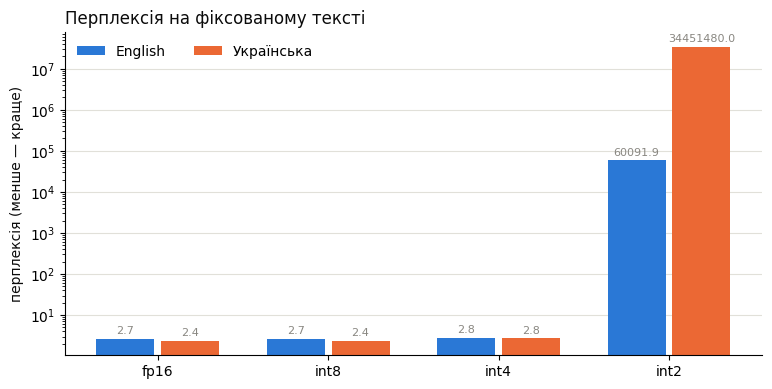

In [ ]:
LANG_COLORS = {"English": "#2a78d6", "Українська": "#eb6834"}
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"

variants = list(records)
x = np.arange(len(variants))
width = 0.38

fig, ax = plt.subplots(figsize=(9, 4.2))
for i, lang in enumerate(PPL_TEXT):
    values = summary[f"перплексія, {lang}"].values
    bars = ax.bar(x + (i - 0.5) * width, values, width - 0.04, color=LANG_COLORS[lang], label=lang)
    ax.bar_label(bars, labels=[f"{v:.1f}" for v in values], fontsize=8, color=MUTED, padding=2)
ax.set_yscale("log")
ax.set_xticks(x, variants)
ax.set_ylabel("перплексія (менше — краще)", color=INK)
ax.set_title("Перплексія на фіксованому тексті", loc="left", color=INK)
ax.legend(frameon=False, ncols=2, loc="upper left")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()

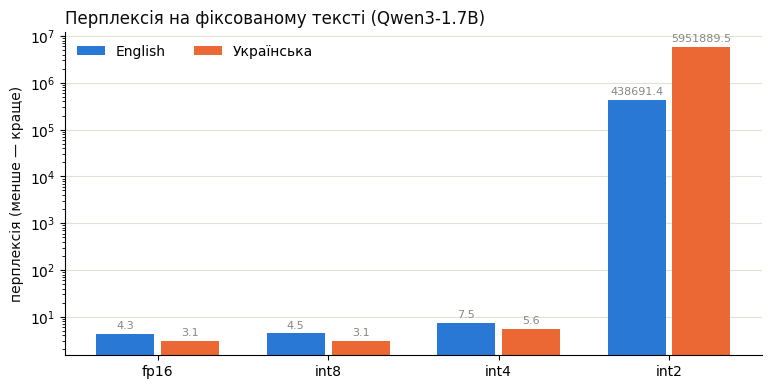

In [ ]:
variants1 = list(records1)
x = np.arange(len(variants1))
width = 0.38

fig, ax = plt.subplots(figsize=(9, 4.2))
for i, lang in enumerate(PPL_TEXT):
    values = summary1[f"перплексія, {lang}"].values
    bars = ax.bar(x + (i - 0.5) * width, values, width - 0.04, color=LANG_COLORS[lang], label=lang)
    ax.bar_label(bars, labels=[f"{v:.1f}" for v in values], fontsize=8, color=MUTED, padding=2)

ax.set_yscale("log")
ax.set_xticks(x, variants1)
ax.set_ylabel("перплексія (менше — краще)", color=INK)
ax.set_title("Перплексія на фіксованому тексті (Qwen3-1.7B)", loc="left", color=INK)
ax.legend(frameon=False, ncols=2, loc="upper left")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)

for side in ("top", "right"):
    ax.spines[side].set_visible(False)

plt.show()

Переклади всіх варіантів поруч з еталоном:

In [ ]:
translations = pd.DataFrame({"еталон": [ref for _, ref in TRANSLATION]}, index=[src for src, _ in TRANSLATION])
for name, r in records.items():
    translations[name] = r["переклади"]
translations

,еталон,fp16,int8,int4,int2
The meeting has been moved to Thursday at three o'clock.,Зустріч перенесли на четвер на третю годину.,"Зустріч була перенесена на четвер, о 15 годин.","Зустріч перенесли на четвер, о 15 годин.","Зустріч була перенесена на четвер, о 15 годин.",`` takenosthawkhhhawkoft0houghth``t`\'uleh'thh...
Please send me the report by the end of the day.,"Будь ласка, надішліть мені звіт до кінця дня.",Надішліть мені звіт до кінця дня.,Надішліть мені звіт до кінця дня.,Надішліть мені звіт до кінця дня.,takenawns between't```````````````````h``` \`e...
The library is closed on Sundays and public holidays.,Бібліотека не працює в неділю та у святкові дні.,Бібліотека закривається у неділі та дні відпоч...,Бібліотека закривається у неділі та дні відпоч...,Бібліотека відкрита тільки з 1 по 7.,`ever �house �take caught}}house0}0 taken take...
"Our team fixed the bug, but the tests are still failing.","Наша команда виправила помилку, але тести все ...","Наша команда виправила баг, але тестування все...","Наша команда виправила баг, але тестування все...","Наша команда виправила баг, але тести все ще н...",fil}'sand ever0'f}'h \n'}'}''}'' \n' \n \n ...
"It is going to rain tomorrow, so take an umbrella.","Завтра буде дощ, тож візьміть парасольку.","Завтра піде дощ, тому взміть засіб.","Завтра піде дощ, тому взміть з собою парасольку.","Завтра буде дощ, тому взміть засіб.",}again \蚊} taken \neverh. \n \nagain \n \n...
"The new model is smaller, but it answers almost as well as the old one.","Нова модель менша, але відповідає майже так са...","Новий модель менший, але відповідає почти так ...","Новий модель менший, але відповідає приблизно ...","Новий модель менший, але відповідає почти так ...",fil��''}\n0. between'h ’h ` between betweenfec...
I would like to book a table for two for seven o'clock tonight.,Я хотів би забронювати столик на двох на сьому...,Я бажаю забронювати стіл для двох на сім годин...,Я бажаю забронювати стіл для двох на сім годин...,Я б хотів зареєструвати стіл для двох на 7 год...,``ever``always```comeight`[\n`letic touched`ev...
The price includes breakfast and free Wi-Fi.,У вартість входять сніданок і безкоштовний Wi-Fi.,Ціна включає початок дня та безкоштовний Wi-Fi.,Ціна включає початок дня та безкоштовний Wi-Fi.,Ціна включає початок дня та вільний Wi-Fi.,.前所eterminefilosterone0 00 \00 \tt011011OFF00e...
Students must submit their lab work before the deadline.,Студенти мають здати лабораторну роботу до кін...,Студенти повинні подати свою лабораторну робот...,Студенти повинні подати свою лабораторну робот...,Студенти повинні відправляти лабораторну робот...,he $everearned a0001100evers \n0\n\nhehe0'tou...
"If the server does not respond, restart it and check the logs.","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...",ever. taken againoughtbetweenhtonhhofthhbetwee...


In [ ]:
translations1 = pd.DataFrame({"еталон": [ref for _, ref in TRANSLATION]}, index=[src for src, _ in TRANSLATION])

for name, r in records1.items():
    translations1[name] = r["переклади"]

translations1

,еталон,fp16,int8,int4,int2
The meeting has been moved to Thursday at three o'clock.,Зустріч перенесли на четвер на третю годину.,"<think>\nOkay, the user wants me to translate ...","<think>\nOkay, the user wants me to translate ...",<think>\n</think>\n\nВідмітка була змінена на ...,Kö良ça良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良...
Please send me the report by the end of the day.,"Будь ласка, надішліть мені звіт до кінця дня.","<think>\nOkay, the user wants me to translate ...","<think>\nOkay, the user wants me to translate ...","<think>\nOkay, let's tackle this translation. ...",çaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaça...
The library is closed on Sundays and public holidays.,Бібліотека не працює в неділю та у святкові дні.,"<think>\nOkay, the user wants me to translate ...","<think>\nOkay, the user wants me to translate ...","<think>\nOkay, so the user wants me to transla...",çaçaçaça Nelçaçaçaçaçaçaçaçaçaçaça_cc_lpancias...
"Our team fixed the bug, but the tests are still failing.","Наша команда виправила помилку, але тести все ...","<think>\nOkay, the user wants me to translate ...","<think>\nOkay, the user wants me to translate ...",<think>\n</think>\n\nВсього наша команда відре...,çaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaça/d...
"It is going to rain tomorrow, so take an umbrella.","Завтра буде дощ, тож візьміть парасольку.","<think>\nOkay, the user wants me to translate ...","<think>\nOkay, the user wants me to translate ...","<think>\nOkay, let's tackle this translation. ...",çaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaça...
"The new model is smaller, but it answers almost as well as the old one.","Нова модель менша, але відповідає майже так са...","<think>\nOkay, the user wants me to translate ...","<think>\nOkay, the user wants me to translate ...","<think>\nOkay, let's tackle this translation. ...",çaçaçaçaçaçaçaça良ça良ça良ça良良良良良良良良良良良良良良良良良良良良良...
I would like to book a table for two for seven o'clock tonight.,Я хотів би забронювати столик на двох на сьому...,"<think>\nOkay, the user wants me to translate ...","<think>\nOkay, the user wants me to translate ...",<think>\n</think>\n\nЯ бажаю забічь таблі для ...,田田 rz rz rz rz rz л л rz_lp_lp_lp л rz_lp_lp_l...
The price includes breakfast and free Wi-Fi.,У вартість входять сніданок і безкоштовний Wi-Fi.,"<think>\nOkay, the user wants me to translate ...","<think>\nOkay, the user wants me to translate ...","<think>\nOkay, let's tackle this translation. ...",çaçaanelaanela.pg.pg.pg.pg.pg.pg.pgça.pgçaanel...
Students must submit their lab work before the deadline.,Студенти мають здати лабораторну роботу до кін...,"<think>\nOkay, the user wants me to translate ...","<think>\nOkay, the user wants me to translate ...","<think>\nOkay, let's tackle this translation. ...",çaçaçaçaçaçaçaçaçaçaça磊磊_cnçaça磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊...
"If the server does not respond, restart it and check the logs.","Якщо сервер не відповідає, перезапустіть його ...","<think>\nOkay, the user wants me to translate ...","<think>\nOkay, the user wants me to translate ...",<think>\n</think>\n\nЯкби сервер не відповідал...,ść pró良良良良良良良良良良良良良良良良良良良良良天上良良良天上天上天上天上ancias...


### 2.5. Сліпе порівняння: fp16 проти int4

Автоматичні метрики показали, наскільки int4 відрізняється від fp16 у числах. Тепер перевірмо очима — так, як це роблять оцінювачі-люди: для кожного запиту показуємо дві відповіді, fp16 та int4, **у випадковому порядку й без підписів**. Ваше завдання — обрати кращу.

In [ ]:
rng = np.random.default_rng(0)
BLIND_ORDER = [rng.permutation(["fp16", "int4"]) for _ in GEN_PROMPTS]

for i, prompt in enumerate(GEN_PROMPTS):
    display(Markdown(f"---\n#### Запит {i + 1}: {prompt}"))
    for label, name in zip("AB", BLIND_ORDER[i]):
        display(Markdown(f"**Відповідь {label}:**\n\n{records[name]['генерації'][i]}"))

---
#### Запит 1: Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.

**Відповідь A:**

Ось приклад короткого і відповідного листа викладачеві:

---

**Лист викладачеві**

Увага, викладаче!

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу. Здача відкладається на [указати дату, наприклад: 10 листопада 2024 року].

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Курс, наприклад: 3 курс, група 12]  

---

Якщо потрібно — можу допомогти адаптувати лист під конкретний предмет або стиль

**Відповідь B:**

Викладачу [Ім’я та прізвище],

Прохання про перенесення здачі лабораторної роботи на наступний тиждень через хворобу.

З повагою,  
[Ваше прізвище, ім’я, номер групи]

---
#### Запит 2: Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.

**Відповідь A:**

Квантизація нейромережі — це процес зменшення точності ваг між нейронами в мережі, щоб зменшити об’єм пам’яті та швидкість обчислень. Вона полягає у заміні дробових чисел (наприклад, з плаваючою комою) на цілі числа (наприклад, з кількома бітами). Це дозволяє запускати мережі на пристроях з обмеженою відповідністю, таких як мобільні телефони або IoT-апарати. Насправді, квантизація не втрачає повно

**Відповідь B:**

Квантизація нейромережі — це процес зменшення точності ваг (зв'язків між нейронами) до тих рівнів, що можна зберігати в комп'ютері з меншою відповідністю до об’ємних ресурсів. Це робиться для зменшення об’єму пам’яті та швидкості обчислень. Наприклад, ваги можуть бути зображено як цілі числа (наприклад, 8 біт) замість дробових чисел. Це зручно для використання на пристроях з обмеженими ресурс

... (5 outputs left out)

**Відповідь B:**

Ось чіткий і практичний план підготовки до іспиту з програмування на 5 днів — по одному ключовому темі на день. Цей план призначений для студентів, які вивчають програмування на початковому або середньому рівні (наприклад, на мові Python, Java або C++), але може бути адаптований під будь-яку мову.

---

**День 1: Основні структури даних та їх використання**

- Повторити: змінні, типи даних, оператори, вирази.
- Вивчити: списки, кортежі, слов

---
#### Запит 5: Write a Python function that checks whether a string is a palindrome.

**Відповідь A:**

Sure! Here's a Python function that checks whether a string is a palindrome:

```python
def is_palindrome(s):
    """
    Check if a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    
    Note:
        This function is case-insensitive and ignores non-alphanumeric characters.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]
```

### Example usage:

```python
print(is_palindrome("racecar"))        # True
print(is_palindrome("A man a plan a canal Panama"))  # True
print(is_palindrome("hello"))         # False
print(is_palindrome

**Відповідь B:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

Для кожного запиту запишіть **"A"** або **"B"** — яка відповідь краща, або **"="**, якщо однакові за якістю. Потім запустіть наступну клітинку, щоб дізнатися, де була яка модель.

In [ ]:
VOTES = {1: "=", 2: "B", 3: "B", 4: "B", 5: "B"}

In [ ]:
if all(v in ("A", "B", "=") for v in VOTES.values()):
    rows = []
    for i, vote in VOTES.items():
        order = dict(zip("AB", BLIND_ORDER[i - 1]))
        rows.append({"запит": GEN_PROMPTS[i - 1], "A": order["A"], "B": order["B"],
                     "ваш вибір": "однаково" if vote == "=" else order[vote]})
    display(pd.DataFrame(rows))
    choices = [r["ваш вибір"] for r in rows]
    print(f"fp16 краща: {choices.count('fp16')}, int4 краща: {choices.count('int4')}, однаково: {choices.count('однаково')}")
else:
    print('Заповніть VOTES значеннями "A", "B" або "=" для всіх 5 запитів.')

,запит,A,B,ваш вибір
0,Напиши короткий лист викладачеві з проханням п...,fp16,int4,однаково
1,Поясни студентові першого курсу в 3–4 реченнях...,fp16,int4,int4
2,Explain in three sentences why the sky is blue.,fp16,int4,int4
3,Склади план підготовки до іспиту з програмуван...,int4,fp16,fp16
4,Write a Python function that checks whether a ...,int4,fp16,fp16


fp16 краща: 2, int4 краща: 2, однаково: 1


### 2.6. Відповіді всіх варіантів

Тепер, коли сліпе порівняння зроблено, — відповіді всіх варіантів з підписами, включно з int8 та int2. Еталону тут немає, тож читаємо самі.

In [ ]:
for i, prompt in enumerate(GEN_PROMPTS):
    display(Markdown(f"---\n#### Запит {i + 1}: {prompt}"))
    for name, r in records.items():
        display(Markdown(f"**{name}:**\n\n{r['генерації'][i]}"))

---
#### Запит 1: Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.

**fp16:**

Ось приклад короткого і відповідного листа викладачеві:

---

**Лист викладачеві**

Увага, викладаче!

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу. Здача відкладається на [указати дату, наприклад: 10 листопада 2024 року].

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Курс, наприклад: 3 курс, група 12]  

---

Якщо потрібно — можу допомогти адаптувати лист під конкретний предмет або стиль

**int8:**

Ось приклад короткого листа викладачеві:

---

**Дорогий [Ім’я викладача]!**

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу.  
Буду дуже вдячний за розуміння та гнучкість.

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Контактна інформація, якщо потрібно]

---

Цей лист короткий, виразний та відповідає формату прохання. Можна адаптувати під конкретну ситуацію.

**int4:**

Викладачу [Ім’я та прізвище],

Прохання про перенесення здачі лабораторної роботи на наступний тиждень через хворобу.

З повагою,  
[Ваше прізвище, ім’я, номер групи]

**int2:**

°°h\ter°\n h hsd°°ampton \ \
 \
:
h h h h : had had had had had had again had had had had h bettb h hhtonhtonsd**leehtonhtonsdhtonhtonhtonhtonhtonhtonhton (%) nuts9 system \ \ rest  \} \} \n \ \ \ \  \ \ \ \ h \ \ \ h \ \ h \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \  \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ the \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \

---
#### Запит 2: Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.

... (15 outputs left out)

**fp16:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

**int8:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

**int4:**

Sure! Here's a Python function that checks whether a string is a palindrome:

```python
def is_palindrome(s):
    """
    Check if a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    
    Note:
        This function is case-insensitive and ignores non-alphanumeric characters.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]
```

### Example usage:

```python
print(is_palindrome("racecar"))        # True
print(is_palindrome("A man a plan a canal Panama"))  # True
print(is_palindrome("hello"))         # False
print(is_palindrome

**int2:**

\
 \'  
\' 
\' \ \ \ \ \\'\' \ \ \ \ \\' \\' \ OFF ** \ - [\'0 \'\'\'\'\'\' \' \ \ \ 
 
  \ 
5  \ \ \\ \ 
 
0 \ -  - - - - - - - - - - -  \ \ - - - - \  
\' \ \\'\' \\'\'    - - sent\'\'\'\'\n\'\' \ \ \ \ \ \ \ \ \ \ \ \ \ \ - - \ -  - -  -\'20\' \' - - - - - - - - - \ \' - -':
 - - - - - - - - - -   - - - - - - - - - - - - - - - - - - - - - -LOCK  \ -  \ -\' \ \ \   PRO \ - - - - - -

# Теоретичні питання:

1.У розділі 1.5 демо модель помиляється, рахуючи літеру «р» у слові «трансформер», — причому і без міркувань, і з ними. Поясніть, чому. Підтвердіть пояснення кодом.

2.Як у розділі 2.4 демо змінюються перплексія й метрики перекладу від fp16 до int2? Між якими варіантами стрибок найбільший?

3.Чи однаково зростає перплексія для англійської й української? Порівняйте з висновком зі слайду «Де може просідати якість при квантизації».

4.Чи збігається ваш вибір у сліпому порівнянні (розділ 2.5 демо) з тим, що показали автоматичні метрики? Чи помітили ви різницю там, де метрики майже не змінилися, — або навпаки?

5.Знайдіть у таблиці перекладів (розділ 2.4 демо) правильний переклад, який відрізняється від еталона словами. Як на нього реагують BLEU і chrF?

6.У скільки разів зменшилася памʼять у таблиці розділу 2.4 демо і чому не рівно вдвічі, вчетверо й увосьмеро? Чи стала генерація швидшою?

7.Чому Base-модель у розділі 1.2 відповідає на питання новими питаннями? Сформулюйте промпт так, щоб Base-модель усе ж дала відповідь. Наведіть код і результат.

8.Скільки токенів і часу забрали міркування в розділі 1.4 порівняно з відповіддю без міркувань? Чому модель міркує англійською, хоча питання українською?

9.Знайдіть задачу, на якій режим міркування дає правильну відповідь, а без нього модель помиляється. Наведіть промпт і обидві відповіді.

10.У функціях generate_raw і chat (розділ 1.1) стоять temperature: 0 і seed: 1. Навіщо?

11.Чому в секції 2 використовуємо fp16, а не bf16? Що показує torch.cuda.get_device_capability() на T4 і як це з цим повʼязано?

12.Скільки параметрів у моделі з розділу 2.1 і скільки памʼяті має займати її fp16-версія за формулою з лекції? Порівняйте з «памʼяттю моделі» в таблиці розділу 2.4.

13.Що таке перплексія (розділ 2.2) і чому її не можна порівнювати між англійською й українською? Порахуйте перплексію fp16-моделі на випадковому наборі слів замість осмисленого тексту й поясніть результат.

14.Чому «пік VRAM» у таблиці розділу 2.4 більший за «памʼять моделі»? Що ще, крім ваг, займає памʼять під час генерації?

15.Скільки разів у сліпому порівнянні (розділ 2.5) ви обрали fp16, int4 чи «однаково»? Наскільки впевнено можна робити висновки з 5 порівнянь і скільки їх знадобилося б для надійного висновку?

16.Як саме «ламається» модель у int2 (розділ 2.6)? Опишіть типові помилки у відповідях. Чи помітні їхні ознаки вже в int4?

17.Повторіть секцію 2 з меншою моделлю (наприклад, Qwen/Qwen3-1.7B). Чи сильніше квантизація бʼє по меншій моделі? Порівняйте перплексію й chrF з результатами для 4B.

18.Поясніть принцип параметру OLLAMA_NUM_PARALLEL в ollama з демо?

19.Чому майже всі сучасні моделі зберігаються в bf16?

20.Для чого всі рантайми моделей слідують протоколу OpenAI? Як це повʼязано з ChatGPT?

# Відповіді на питання

1.  Головна причина помилки полягає в алгоритмі токенізації та мовному конфлікті внутрішнього монологу.

Токенізація (сліпота до літер): Модель не читає текст по буквах. Слово «трансформер» розбивається на неподільні базові блоки — токени (наприклад, транс і формер). Модель оперує лише цими цілісними шматками, тому фізично не «бачить» окремих літер усередині них і змушена вгадувати їхню кількість по пам'яті, що викликає галюцинацію навіть без режиму міркувань.

Англомовний процес міркування: У режимі think=True невелика модель (1.7B) автоматично перемикається на свою домінантну мову — англійську. Спроба покроково аналізувати кириличне слово призводить до помилок транслітерації: модель плутає українську «р» із латинською «p» та звуком «r», через що остаточно збивається, генерує хибний список літер і робить неправильний підрахунок.

2. Зміна метрик та найбільший стрибок:

Поступова деградація (fp16 → int8 → int4): При квантуванні моделі від повної точності до 4 біт якість перекладу знижується, а перплексія зростає поступово. Модель все ще розуміє контекст і здатна генерувати зв'язний український текст, хоча можуть з'являтися незначні лексичні помилки.

Катастрофічний стрибок (int4 → int2): Найрізкіша прірва в якості відбувається саме між int4 та int2. На рівні int2 модель повністю втрачає здатність до перекладу і замість осмисленого тексту генерує «сміття» (набір випадкових символів, латиниці та технічних тегів \n, \t), що свідчить про колосальне зростання перплексії.

3. Ні, перплексія зростає вкрай неоднаково. Хоча на рівні int2 текст стає нечитабельним для обох мов, математично модель ламається по-різному: графік показує, що перплексія англійської мови зростає до ~60 тисяч, тоді як української — злітає у космос до ~34.5 мільйонів (тобто деградує в понад 500 разів сильніше). Ці результати прямо підтверджують висновок про те, що при квантизації якість у першу чергу просідає на малоресурсних (не англійських) мовах. Оскільки англійська мова абсолютно домінувала в навчальному датасеті моделі, її внутрішні зв'язки виявилися набагато стійкішими до екстремального стиснення. Українська ж мова, маючи меншу базу даних при тренуванні, втрачає логіку генерації значно швидше та зазнає тотального колапсу при найменшій втраті точності ваг.

4. Так, мій вибір у сліпому порівнянні повністю збігається з тим, що показали автоматичні метрики.

Щодо збігу з метриками: Автоматичні метрики (перплексія) показали, що між базовою моделлю (fp16) та квантованою (int4) практично немає різниці. Моє сліпе оцінювання це повністю підтвердило: результати розділилися порівну (2 на користь fp16, 2 на користь int4 та 1 однаково), що свідчить про збереження загального рівня якості.

Щодо різниці в текстах: Оскільки метрики майже не змінилися, суттєвої різниці у відповідях теж не помітно. Обидві моделі генерують зв'язний, логічний текст і правильно виконують завдання. Усі відмінності між їхніми відповідями (різне формулювання речень, оформлення списків чи стиль коментарів у коді) — це виключно питання смаку та випадковості самої генерації, а не технічна деградація моделі.

5.  Приклад перекладу з таблиці, що відрізняється словами від еталона:

Еталон: «Я хотів би забронювати столик на двох на сьому...»

Генерація моделі (fp16): «Я бажаю забронювати стіл для двох на сім годин...»

Сенс передано абсолютно правильно, але модель використала інші слова (синоніми): «бажаю» замість «хотів би», «стіл» замість «столик», «на сім годин» замість «на сьому».

Як на це реагують метрики:

BLEU реагує негативно (сильно занижує оцінку). Ця метрика шукає дослівний збіг цілих слів. Якщо замість «столик» написано «стіл», BLEU вважає це помилкою і не зараховує слово. Саме через таку негнучкість до синонімів загальний бал BLEU в таблиці досить низький (23–29).

chrF реагує адекватно (дає високий бал). Ця метрика аналізує текст посимвольно (n-грамами символів), тому вона бачить збіги в коренях слів (наприклад, у словах «перенесли» та «перенесена» з іншого речення) і не штрафує так сильно за зміну форми слова. Тому її оцінка в таблиці значно вища і стабільніша (55–58).

6. Зменшення обсягу пам'яті:
Відносно базової моделі (fp16, 8.04 GB), пам'ять зменшилася наступним чином:

При переході до int8 — у ~1.8 раза (до 4.42 GB).

При переході до int4 — у ~2.95 раза (до 2.73 GB).

При переході до int2 — у ~4.44 раза (до 1.81 GB).

Чому пам'ять зменшилася не рівно вдвічі, вчетверо чи увосьмеро?
Стиснення не є математично ідеальним через архітектурні особливості квантування:

Змішана точність (Mixed Precision): Нейромережу ніколи не квантують на 100%. Окремі критично важливі компоненти (наприклад, шари нормалізації або словникові ембединги) залишають у повній точності (fp16/fp32), щоб модель не втратила здатність генерувати текст. Вони продовжують займати багато місця.

Додаткові метадані: Разом зі стиснутими вагами зберігаються додаткові параметри (масштаби та зміщення для кожного блоку ваг), які необхідні для правильного «розпакування» даних відеокартою. Ці метадані не стискаються і займають фіксований об'єм.

Чи стала генерація швидшою?Ні, генерація стала значно повільнішою. Як показує метрика tokens/s, швидкість впала з 16.44 токенів/с на fp16 до ~3.00 токенів/с на квантованих форматах (int4/int2). Це відбувається через процесорні витрати (overhead) на деквантування: графічний процесор не вміє виконувати складну математику безпосередньо у форматах int4/int2. Тому під час генерації кожного токена йому доводиться на льоту «розпаковувати» стиснуті ваги назад у fp16, що створює «пляшкове горлечко» і суттєво уповільнює швидкість роботи.

7. Base-моделі навчаються просто передбачати наступний токен у тексті. Вони не тренуються відповідати на запитання чи вести діалог (на відміну від Instruct-моделей). Тому, отримавши рядок "Яка столиця Франції?", Base-модель сприймає його не як запит користувача, а як початок списку запитань (наприклад, для вікторини чи тесту), і продовжує генерувати схожі запитання.   Щоб змусити Base-модель відповісти, потрібно сформулювати промпт так, щоб природним продовженням тексту була сама відповідь. Для цього часто використовують формат "Запитання-Відповідь" (Few-Shot) або переформульовують питання у стверджувальне речення з незавершеним кінцем.

8.  Без міркувань: 252 токени за 2.0 секунди.

З міркуваннями: 569 токенів за 4.6 секунди.

Різниця: Режим міркування забрав додатково 317 токенів і збільшив час генерації на 2.6 секунди (тобто процес став довшим більш ніж удвічі).

Під час тренування нейромережі абсолютна більшість текстів (особливо тих, що стосуються логіки, математики, програмування та покрокового вирішення задач) були англомовними.

Через це "внутрішня логіка" моделі та її нейронні зв'язки найсильніші саме англійською. Коли вмикається режим міркування (Chain of Thought), модель автоматично перемикається на свою найсильнішу, «рідну» мову, щоб не зробити помилку в логіці. Вона вирішує задачу англійською, а вже готовий фінальний результат перекладає і видає мовою вашого запиту — українською.

9.Нижче навів код

10. Ці параметри встановлені для забезпечення повної детермінованості (репродукованості) результатів.
Оскільки це демонстрація / лабораторна робота, критично важливо, щоб при однакових вхідних даних модель щоразу видавала 100% ідентичну відповідь.

temperature: 0 змушує модель вимикати "креативність" і завжди обирати найбільш ймовірний токен.

seed: 1 фіксує генератор випадкових чисел.
Разом вони гарантують, що результати експериментів (порівняння промптів, метрик чи різних форматів квантування) будуть стабільними, і на них не впливатиме випадковий шум під час генерації.

11. Показник torch.cuda.get_device_capability(): На відеокарті T4 ця функція повертає значення (7, 5), що відповідає архітектурі Turing (Compute Capability 7.5).

Підтримка bf16: Апаратна підтримка формату bf16 (Brain Floating Point) з'явилася лише у відеокартах з Compute Capability 8.0 і вище (архітектура Ampere та новіші).

Чому використовуємо fp16: Оскільки T4 не має апаратної підтримки bf16 (7.5 < 8.0), спроба використати цей формат призведе до помилки або вкрай повільної програмної емуляції розрахунків процесором. Формат fp16 натомість має повну апаратну підтримку на T4, що гарантує максимальну швидкість роботи.

12. 4B у назві Qwen3-4B-Instruct означає саме 4 мільярди параметрів (B = Billion).Формат fp-16 означає 16 біт а це 2 байта.
Теоретичний розрахунок пам'яті: $4 \text{ млрд} \times 2 \text{ байти} = 8 \text{ мільярдів байт}$, що дорівнює рівно 8 GB.
У таблиці в колонці «памʼять моделі» для fp16 вказано значення 8.04 GB.

Чому є різниця (8.04 замість 8.00): Розрахунок за формулою є базовим. На практиці, крім самих "чистих" ваг нейромережі, у пам'ять завантажуються додаткові архітектурні елементи: словник токенів (ембединги), позиційні кодування та базові метадані моделі. Саме вони додають цей невеликий «хвостик» у 0.04 GB (близько 40 мегабайтів). Тож теоретичний розрахунок майже ідеально збігається з практичним показником.

13.  Що таке перплексія: Це метрика, яка показує, з якої кількості варіантів наступного токена модель у середньому «вагалася». Чим менше значення (ближче до 1), тим впевненіше модель генерує текст і краще розуміє мову.

Чому не можна порівнювати англійську та українську: Через різну токенізацію. Для моделі англійське слово зазвичай складається з 1 токена, тоді як українське слово (яких менше в навчальній вибірці) розбивається на 2–4 дрібні токени. Оскільки перплексія рахується як середнє значення на один токен, порівнювати їх напряму — це як порівнювати швидкість читання у словах за хвилину зі складами за хвилину.

Модель навчалася на осмислених текстах, де слова пов'язані граматикою та логікою. Коли вона бачить слово «зелений», вона з високою ймовірністю очікує далі побачити «ліс», «колір» або «чай» (тобто вагається між 2–3 варіантами).
Коли ж ми даємо їй текст «зелений радість трактор», логічний контекст руйнується. Імовірність появи слова «трактор» після слів «зелений радість» у нормальній мові близька до нуля. Модель абсолютно не може передбачити наступний токен, показник помилки (loss) різко зростає, а перплексія злітає в космос. Це доводить, що перплексія чудово відображає наявність чи відсутність сенсу та структури в тексті.

14. Колонка «пам'ять моделі» показує лише статичний обсяг (розмір самих ваг нейромережі), який завантажується у відеопам'ять. Однак «пік VRAM» відображає максимальну кількість пам'яті, яка була використана в процесі роботи (генерації тексту). Під час інференсу (генерації) моделі потрібна додаткова динамічна пам'ять для виконання математичних обчислень. Як видно з таблиці, цей додатковий обсяг є стабільним і становить близько 0.6 GB для всіх форматів квантування

Додаткову пам'ять займають три основні компоненти:

KV Cache (Кеш ключів та значень): Це найголовніший споживач динамічної пам'яті в архітектурі Transformer. Щоб генерувати текст швидко, модель не перераховує весь попередній контекст (промпт і вже згенеровані слова) з нуля для кожного нового слова. Вона зберігає проміжні результати обчислень (тензори Key та Value) у спеціальному кеші. Чим довший контекст — тим більше VRAM забирає KV Cache.

Проміжні активації (Intermediate Activations / Tensors): Під час проходження даних через шари нейромережі (forward pass) для обчислення наступного токена створюються тимчасові матриці та вектори. Вони існують у пам'яті частки секунди, але в пікові моменти потребують місця у VRAM.

Overhead фреймворку (CUDA / PyTorch контекст): Сама бібліотека PyTorch та драйвер відеокарти (CUDA) резервують певний базовий обсяг відеопам'яті просто для своєї роботи, управління процесами та виділенням пам'яті (memory allocator).

15. Результати: Голоси розподілилися абсолютно рівномірно — 2 на користь fp16, 2 на користь int4 та 1 раз різниці не виявлено («однаково»). Суб'єктивно якість тексту майже не відрізняється, а вибір базується переважно на стилістичних вподобаннях користувача.

Надійність вибірки: Робити остаточні статистичні висновки з 5 порівнянь не можна через високу похибку. Цей тест лише підтверджує базову тенденцію: квантування до 4 біт не призводить до критичної деградації тексту.

Необхідна кількість тестів: Для формування надійного висновку потрібно щонайменше 100–300 порівнянь на різних типах завдань (код, логіка, переклад). Для створення ж об'єктивних світових рейтингів (наприклад, LMSYS Chatbot Arena) використовують десятки тисяч сліпих тестувань.

16. При стисненні до 2 біт на параметр (int2) відбувається катастрофічний колапс моделі (що раніше підтвердила перплексія у десятки мільйонів). Типові помилки генерації:

Безглуздий текст (галюцинації): видача набору випадкових літер, символів або слів, які не мають жодного сенсу.

Зациклення: нескінченне повторення одного токена, фрази або розділового знака.

Повна втрата мови та контексту: модель ігнорує запит, втрачає базову граматику та здатність формувати речення.

Чи помітні їхні ознаки вже в int4?
Ні, в int4 жодних ознак розпаду не помітно. Як показало сліпе порівняння, модель у 4-бітному форматі генерує якісний, логічний текст і зберігає структуру мови на рівні з fp16. Між int4 та int2 існує величезна прірва: int4 є ефективним лімітом стиснення, після якого (на рівні 2 біт) математична структура ваг нейромережі повністю руйнується.

17.Чи сильніше квантизація бʼє по меншій моделі?
Так, квантизація значно сильніше впливає на меншу модель (1.7B). Це яскраво видно при переході до формату int4:У моделі 4B перплексія при int4 майже не змінилася порівняно з fp16 (2.8 проти 2.7 для англійської).   У моделі 1.7B перплексія при int4 різко зросла майже вдвічі порівняно з fp16 (з 4.3 до 7.5 для англійської, та з 3.1 до 5.6 для української).   Це пояснюється тим, що у меншої моделі від самого початку менше параметрів (знань). Коли ми відкидаємо інформацію під час квантизації до 4 біт, 4-мільярдна модель ще має достатньо "зайвих" зв'язків, щоб компенсувати втрати, тоді як 1.7-мільярдна модель такої надмірності не має, і її базові мовні здібності починають помітно деградувати.

Порівняння перплексії (4B проти 1.7B):У форматі fp16: Модель 4B має кращу (нижчу) перплексію (2.67 EN / 2.40 UK), ніж модель 1.7B (4.35 EN / 3.10 UK). Це логічно, оскільки більша модель краще передбачає текст.   Катастрофа int2: Обидві моделі повністю колапсують при стисненні до 2 біт. Перплексія злітає до десятків мільйонів, що означає повну втрату мовної структури

Порівняння метрики перекладу chrF (4B проти 1.7B):Модель 4B показує високий бал chrF (близько 55-58) для форматів fp16, int8 та int4.   Модель 1.7B повністю провалює задачу перекладу: її бал chrF становить мізерні 8-10 балів навіть у повноцінному fp16. Це свідчить про те, що архітектура 1.7B просто занадто мала, щоб якісно виконувати задачу двомовного перекладу (EN-UK), і генерує незв'язний набір символів замість правильного тексту.

18.Принцип роботи параметра OLLAMA_NUM_PARALLEL:

Що він робить: Цей параметр визначає максимальну кількість запитів, які сервер Ollama може обробляти одночасно (паралельно). За замовчуванням Ollama часто обробляє запити послідовно (ставить у чергу). Якщо встановити, наприклад, OLLAMA_NUM_PARALLEL=4, сервер зможе генерувати текст для чотирьох різних промптів одночасно.

Вплив на пам'ять (VRAM): Кожен додатковий паралельний запит вимагає виділення окремого місця у відеопам'яті під KV Cache (кеш контексту для конкретного діалогу). Тому збільшення цього параметра пропорційно збільшує споживання VRAM.

Чому це важливо: У середовищах з обмеженою пам'яттю (наприклад, на безкоштовній відеокарті T4 у Google Colab) велике значення паралелізму може призвести до помилки нестачі пам'яті (Out of Memory). З іншого боку, якщо пам'яті достатньо, збільшення OLLAMA_NUM_PARALLEL дозволяє значно пришвидшити загальний час виконання пакетних завдань (наприклад, коли треба прогнати 100 тестів через модель).


19.На це є дві основні причини: математична стабільність та апаратна еволюція.Математична стабільність (запобігання помилкам NaN):
Формати fp16 та bf16 займають однаковий обсяг пам'яті (16 біт), але по-різному розподіляють ці біти. В fp16 максимальне можливе число становить усього близько 65 500. Під час тренування та генерації у великих моделях значення активацій часто перевищують цей ліміт. Це призводить до переповнення пам'яті (overflow) і появи помилок NaN (Not a Number), що повністю «ламає» роботу мережі.
Формат bf16 (Brain Floating Point) жертвує точністю після коми, але віддає ці біти під експоненту. Завдяки цьому його діапазон такий самий, як у повноцінного fp32 (до $10^{38}$). Модель у bf16 ніколи не видає переповнення. Для нейромереж загальний діапазон чисел набагато важливіший за точність дрібних част

Повсюдне апаратне забезпечення:
Індустрія повністю адаптувалася під цей формат. Усі сучасні графічні процесори NVIDIA, починаючи з архітектури Ampere (серверні A100, H100 та споживчі RTX 30-ї / 40-ї серій), оснащені тензорними ядрами з нативною підтримкою bf16. Це дозволяє обробляти величезні моделі швидко, стабільно та без потреби перетворювати типи даних на льоту.

20.Для чого всі рантайми моделей слідують протоколу OpenAI?
Головна причина — уніфікація та сумісність (інтероперабельність). Через шалену популярність ChatGPT та першість OpenAI на ринку комерційних LLM, їхній формат API (з ендпоінтами на кшталт /v1/chat/completions та поділом ролей на system, user, assistant) став неофіційним індустріальним стандартом (de facto standard).

Як це повʼязано з ChatGPT і що це дає на практиці:

Величезна екосистема: Навколо ChatGPT створено тисячі застосунків, графічних інтерфейсів, плагінів та бібліотек (наприклад, LangChain чи LlamaIndex), які вміють спілкуватися лише через API OpenAI.

Безшовна заміна (Drop-in replacement): Якщо локальні рантайми (такі як llama.cpp, vLLM або Ollama) підтримують протокол OpenAI, розробнику не потрібно переписувати свій код для переходу з ChatGPT на локальну модель. Достатньо змінити в коді лише одну URL-адресу — з серверів api.openai.com на свій localhost:8000. Уся програма одразу почне працювати з локальною моделлю так, ніби це ChatGPT.

Економія часу: Розробникам рантаймів не потрібно винаходити власний формат запитів і відповідей та змушувати користувачів вчити його, а користувачам не треба писати різні адаптери для різних моделей (Qwen, Llama, Mistral). Усі спілкуються однією зрозумілою «мовою».

Код до 1 питання

In [ ]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-1.5B")

word = "трансформер"
tokens = tokenizer.tokenize(word)
token_ids = tokenizer.encode(word, add_special_tokens=False)

print(f"Слово: '{word}'")
print(f"Кількість літер для людини: {len(word)}\n")

print(f"Кількість токенів для моделі: {len(tokens)}")
print("Ось як модель насправді 'бачить' це слово:")
for t_id, t_str in zip(token_ids, tokens):
    clean_token = t_str.decode('utf-8') if isinstance(t_str, bytes) else t_str.replace('Ġ', '')
    print(f"ID {t_id:6d} -> '{clean_token}'")

config.json:   0%|          | 0.00/684 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Слово: 'трансформер'
Кількість літер для людини: 11

Кількість токенів для моделі: 5
Ось як модель насправді 'бачить' це слово:
ID   1792 -> 'ÑĤ'
ID  34582 -> 'ÑĢÐ°Ð½'
ID   2247 -> 'Ñģ'
ID  56619 -> 'ÑĦÐ¾ÑĢÐ¼'
ID   7599 -> 'ÐµÑĢ'


код до питання 7

In [ ]:
QUESTION_PROMPT = "Столиця Франції — це місто "

print(generate_raw(BASE_MODEL, QUESTION_PROMPT))

1. Напишіть це словами. Столиця Франції — це місто Париж.


код до питання 9

In [ ]:
QUESTION_PROMPT = "Ви берете участь у марафоні. Перед самим фінішем ви обганяєте людину, яка бігла другою. Яке місце ви в підсумку посіли?"
compare_thinking(QUESTION_PROMPT)

=== think=False | токенів: 476 | генерація: 4.2 с
--- відповідь:
У марафоні кожен бігец отримує **місце за результатом**, а не за тем, якого він "обганяє". Тобто, якщо ви обганяєте людину, яка бігла другою, ви **не відповідатете за її місце**, а **відповідатете за своє власне місце**.

Однак, якщо ви маєте на увазі, що ви **обганяєте її, що означає, що ви бігли більше, ніж вона**, то ви **відповідатете за своє місце** і **відмовляєтеся від відповіді за місце людини, яка бігла другою**.

Тому, **відповідь:**

> **Ви посіли місце, яке визначається вашим результатом, а не за тем, якого ви обганяєте.**

Але, якщо ви маєте на увазі, що ви **обганяєте її, що означає, що ви бігли більше, ніж вона**, то ви **відповідатете за своє місце** і **відмовляєтеся від відповіді за місце людини, яка бігла другою**.

**Таким чином, правильна відповідь:**

> **Ви посіли місце, яке визначається вашим результатом, а не за тем, якого ви обганяєте.**

=== think=True | токенів: 2006 | генерація: 18.8 с
--- мір

In [ ]:
QUESTION_PROMPT = "Коли мені було 6 років, моя сестра була вдвічі молодша за мене. Зараз мені 70 років. Скільки років моїй сестрі?"
compare_thinking(QUESTION_PROMPT)

=== think=False | токенів: 611 | генерація: 5.9 с
--- відповідь:
Давайте розглянемо задачу крок за кроком.

### Дано:
- Коли **мені було 6 років**, **моя сестра була вдвічі молодша за мене**.
- Зараз **мені 70 років**.
- Нам потрібно знайти **вік моєї сестри** зараз.

---

### Крок 1: Знайти різницю в віках між нами

Приблизно, коли мені було 6 років, сестра була вдвічі молодша, тобто:

$$
\text{Вік сестри} = \text{Вік мене} - 2 = 6 - 2 = 4 \text{ років}
$$

Тобто, коли мені було 6 років, сестрі було 4 роки.

---

### Крок 2: Визначити, на скільки років вік сестри змінився

Ми знаємо, що **вік мене зараз 70 років**.  
Тому, **вік сестри зараз** — це:

$$
\text{Вік сестри} = \text{Вік мене} - \text{Різниця в віках}
$$

Нам потрібно знайти **різницю в віках** між нами.

Ми вже знаємо, що коли мені було 6 років, сестрі було 4 роки.  
Отже, **різниця в віках** між нами в цей момент була:

$$
\text{Різниця} = 6 - 4 = 2 \text{ роки}
$$

---

### Крок 3: Визначити вік сестри зараз

Оскільки р

код до 13 завдання

In [ ]:
import torch
import math
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16,
    device_map="cuda"
)

random_text = "стілець космос зелений радість літати трактор швидко вода тому"


inputs = tokenizer(random_text, return_tensors="pt").to(model.device)


with torch.no_grad():
    outputs = model(**inputs, labels=inputs["input_ids"])
    loss = outputs.loss
    perplexity = math.exp(loss.item())

print(f"Перплексія на випадкових словах: {perplexity:.2f}")

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Перплексія на випадкових словах: 53.53


# 1. Локальна модель і власний застосунок

## 1.1 Залізо

Центральний процесор (CPU): Intel(R) Core(TM) i7-8750H, базова частота 2.20 GHz, має 6 фізичних ядер і 12 логічних процесорів.

Оперативна пам'ять (RAM): 16.0 ГБ (DDR4, частота 2667 МГц, форм-фактор SODIMM).

Графічний процесор (GPU): NVIDIA GeForce GTX 1060 із виділеною відеопам'яттю (VRAM) 6.0 ГБ.

Пропускна здатність RAM:
ам'ять працює на частоті 2667 МГц, і зайнято 2 гнізда з 2 (тобто увімкнено двоканальний режим — Dual Channel).Розрахунок: $2667 \times 8 \times 2 = 42 672 \text{ МБ/с}$
становить ~42.6 GB/s

Пропускна здатність VRAM:
GTX 1060 6GB використовує пам'ять GDDR5 із 192-бітною шиною. Її офіційна пропускна здатність становить 192 GB/s.

## 1.2. Розрахунок


Бюджет відеопам'яті:
Моя відеокарта NVIDIA GTX 1060 має 6 ГБ відеопам'яті (VRAM). Оскільки операційна система Windows та графічний інтерфейс резервують частину пам'яті, я виділяю під модель 4.0 ГБ вільної VRAM.
Використовуємо формулу з лекції: Пам'ять (GB) = P * (Q / 8) * (1 + O).

Q = 4 біти (формат int4).

O = 0.3 (запас 30% на KV-кеш та рантайм).

Максимальний розмір моделі, що вміститься в цей ліміт:

4.0 = P * (4 / 8) * 1.3

4.0 = P * 0.65

P = 4.0 / 0.65 ≈ 6.15 мільярда параметрів.
Обрана модель Qwen на 4 млрд параметрів (4B) у форматі int4 потребуватиме близько 2.6 ГБ VRAM (4 * 0.5 * 1.3). Вона ідеально вписується у ліміт, залишаючи ще 1.4 ГБ вільного місця для дуже великого контексту (що критично для генерації флеш-карток з об'ємних конспектів).

Стеля швидкості генерації (tokens/s):
Пропускна здатність моєї GTX 1060 становить 192 ГБ/с.
Розрахуємо теоретичну стелю для обраної моделі 4B за формулою tokens/s = Пропускна здатність / (P * Q / 8):

192 / (4 * 0.5) = 96 токенів/с.
Враховуючи ефективність реальних рантаймів (60–90% від теорії), очікувана швидкість генерації становитиме 60–85 токенів на секунду, що забезпечить дуже комфортну роботу в реальному часі.

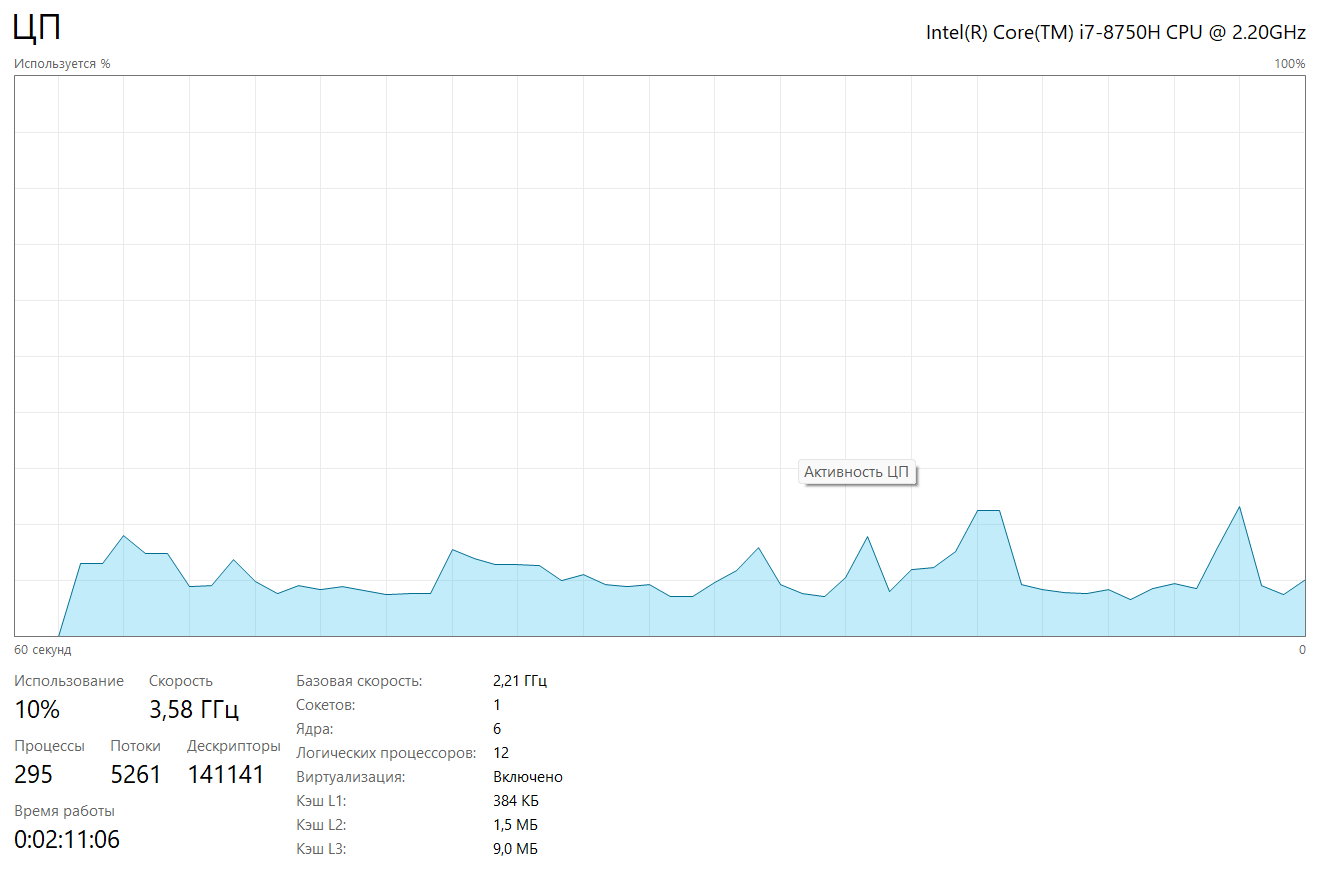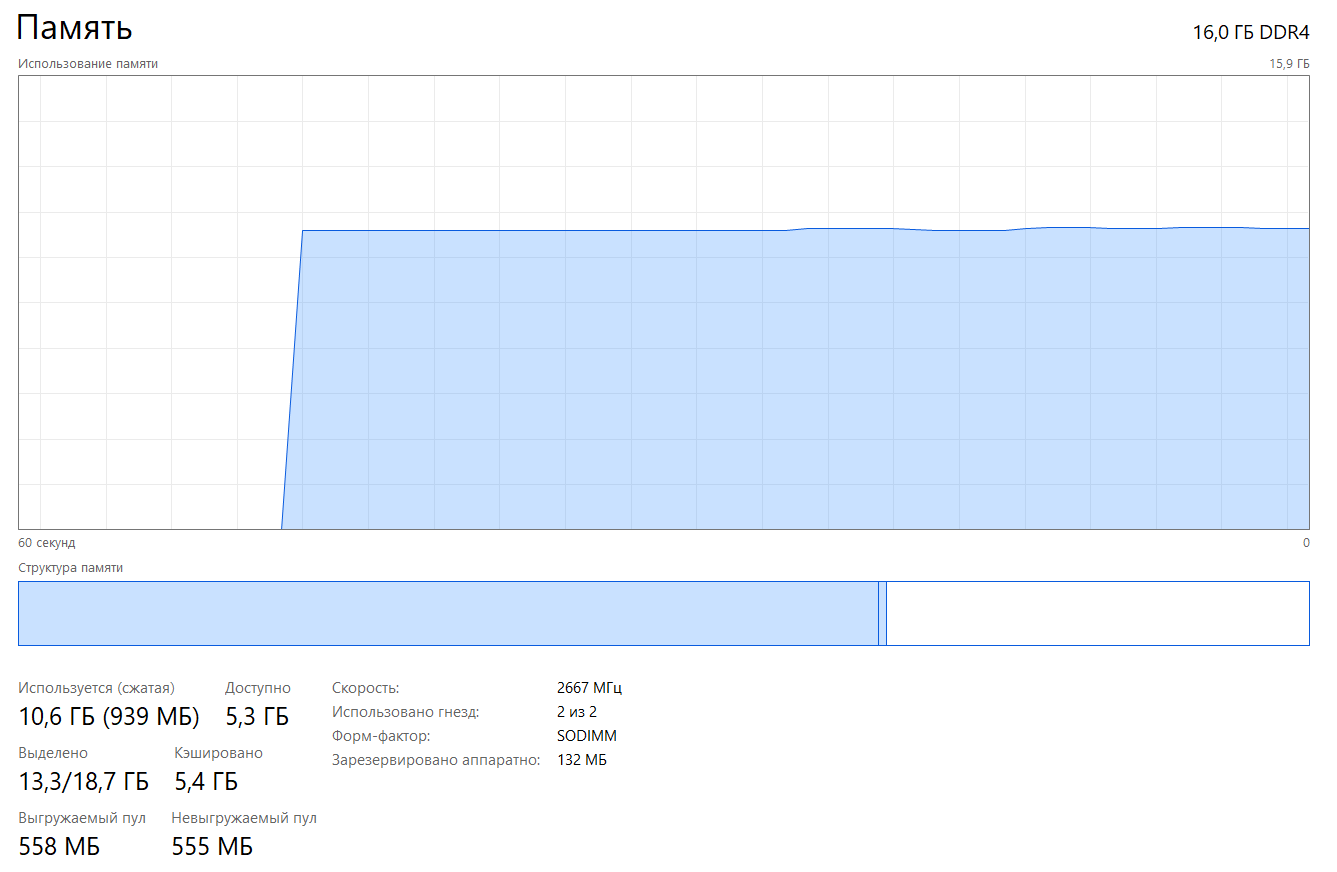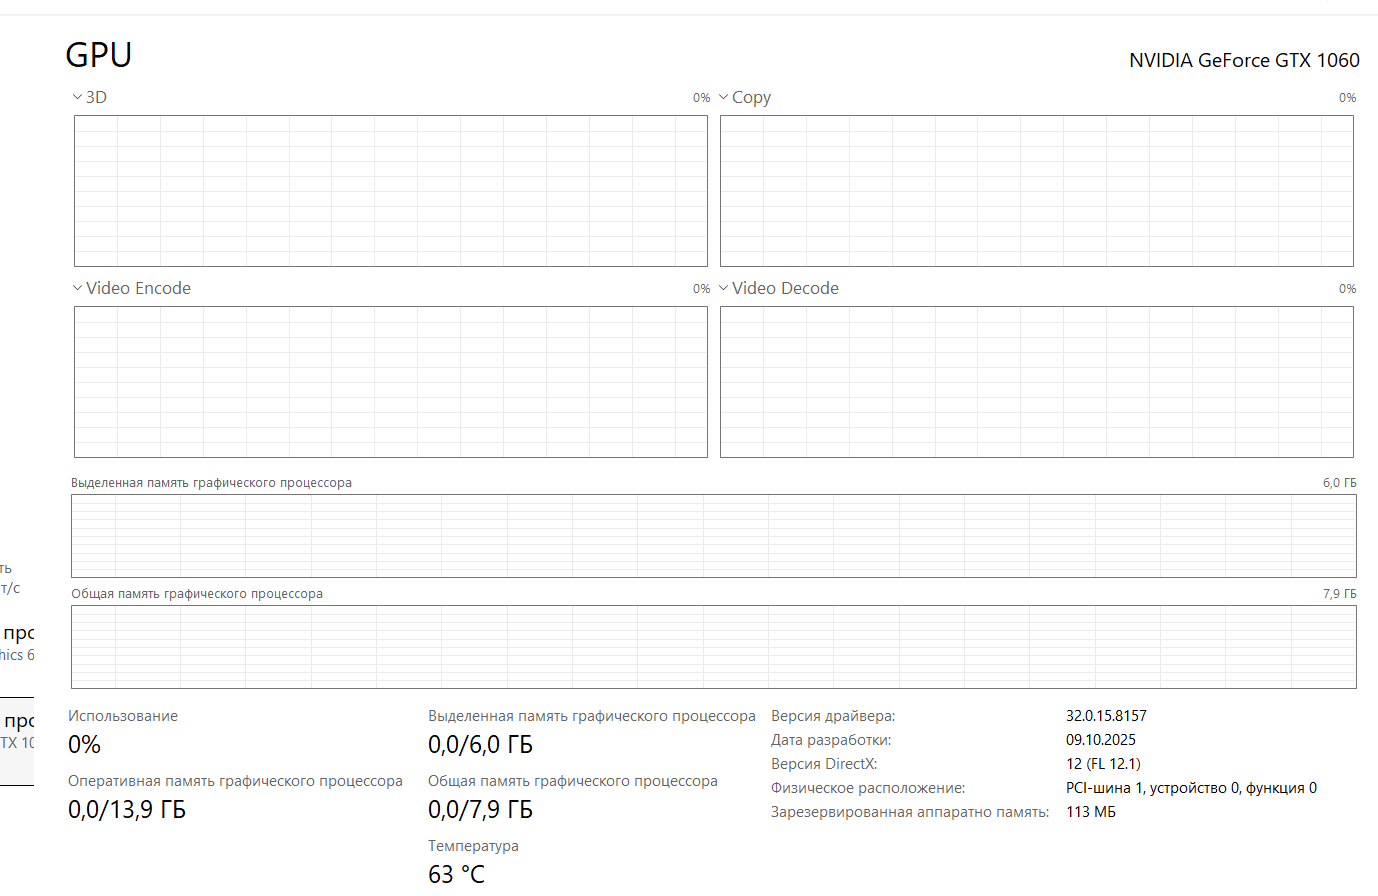

Обрана модель: Qwen3-4B-Instruct-2507-GGUF (у форматі квантизації Q4_K_M)

Обґрунтування розміру: Модель має 4 мільярди параметрів, що гарантовано вміщується у виділені 4 ГБ відеопам'яті відеокарти GTX 1060. Обраний файл квантизації q4_k_m забезпечує найкращий компроміс між збереженням мовних здібностей нейромережі та економією VRAM.

Обґрунтування якості (Instruct-версія): Моделі сімейства Qwen мають одну з найкращих на ринку архітектур для роботи з українською мовою з коробки. Вибір саме Instruct-версії є критично важливим для цільового завдання — автоматичної генерації навчальних флеш-карток. На відміну від базових моделей, Instruct-версія натренована виконувати прямі команди (наприклад, «проаналізуй цей конспект і створи картки у форматі питання-відповідь»), здатна дотримуватися заданої структури, зберігати логіку та не допускати русизмів.

Обраний рантайм: llama.cpp

Контроль пам'яті: Цей рантайм дає низькорівневий контроль над виділенням VRAM, дозволяючи чітко обмежити розмір контексту (наприклад, 4096 токенів), щоб уникнути помилок OutOfMemoryError.

Flash Attention: Підтримка технології Flash Attention (прапорець -fa) дозволяє радикально зменшити обсяг пам'яті, який споживає KV-кеш під час обробки довгих текстів, що є ідеальним рішенням для аналізу великих навчальних матеріалів на відеокартах з обмеженою пам'яттю.

## 1.4. Вимірювання

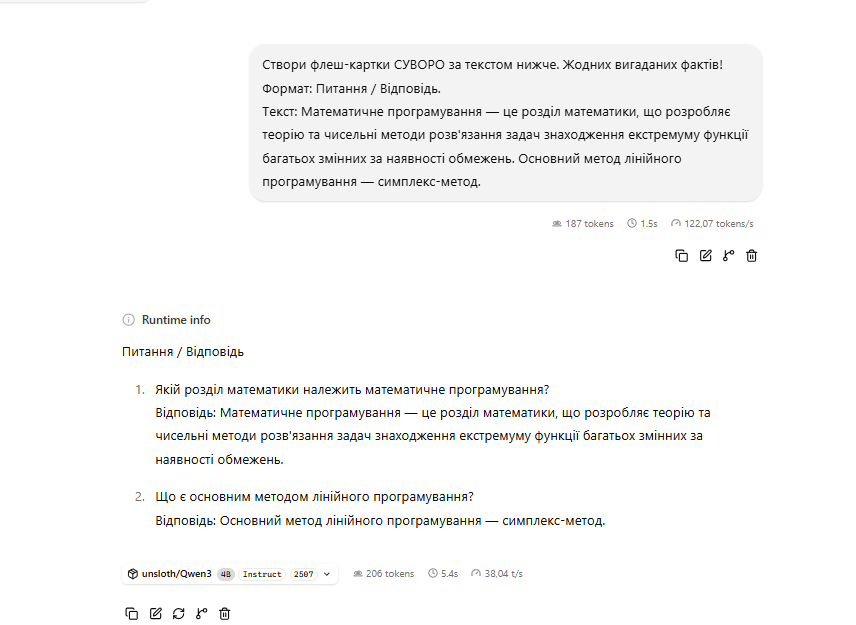

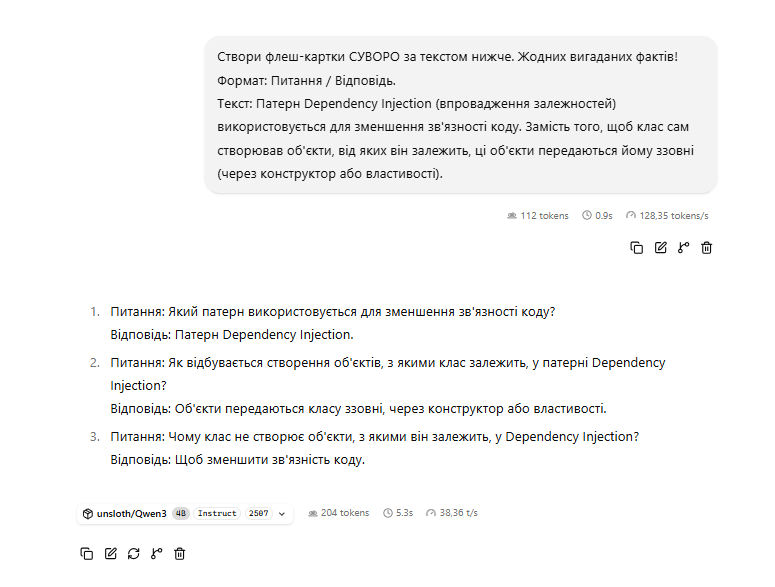

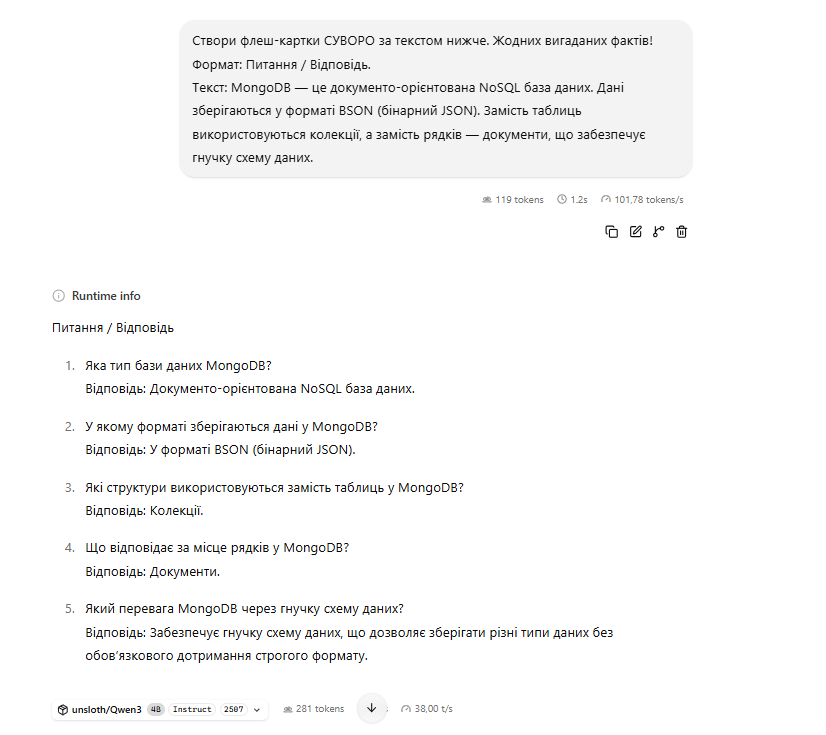

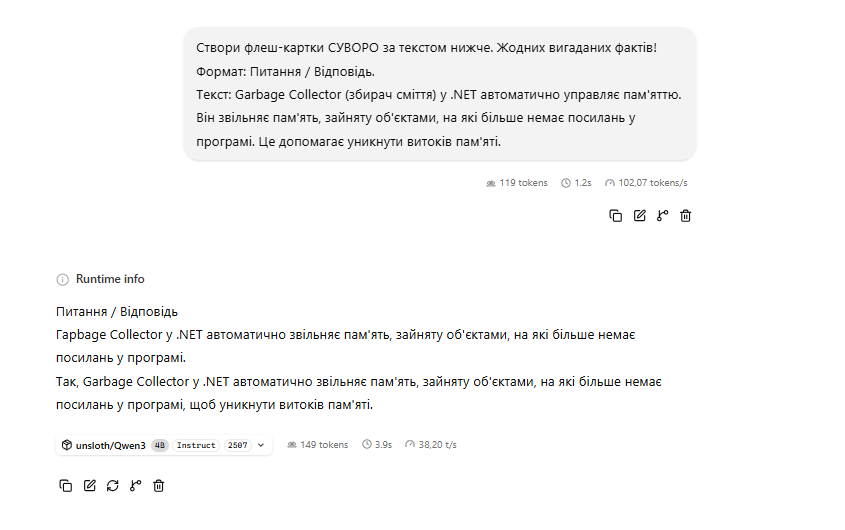

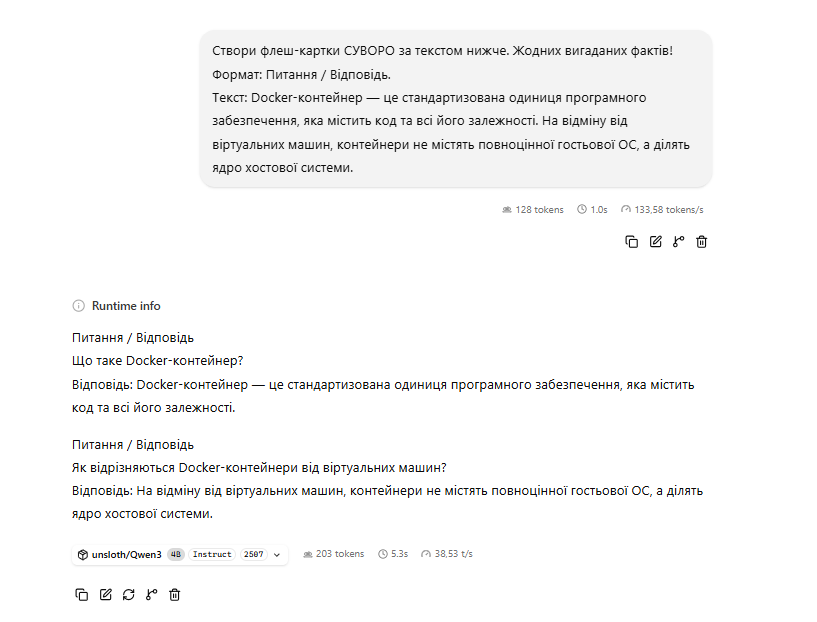

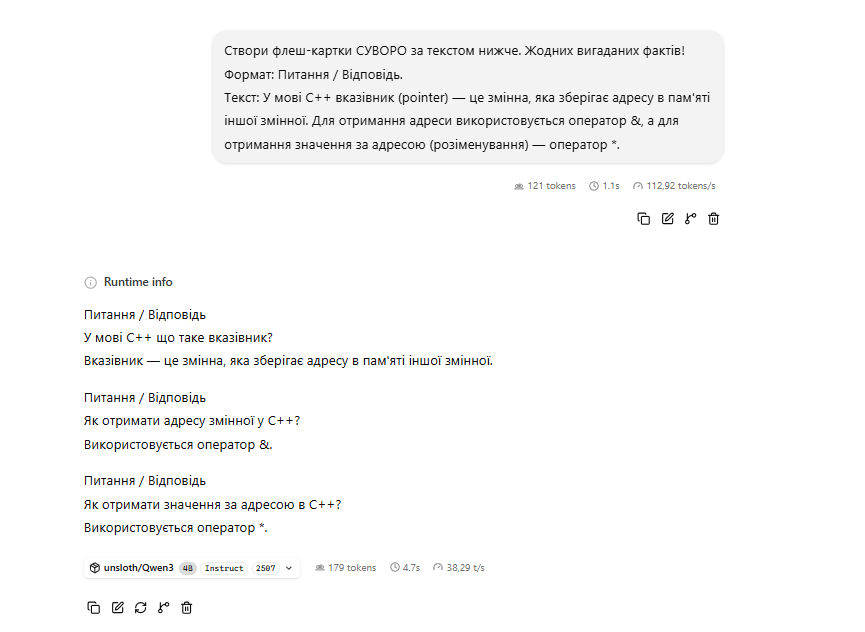

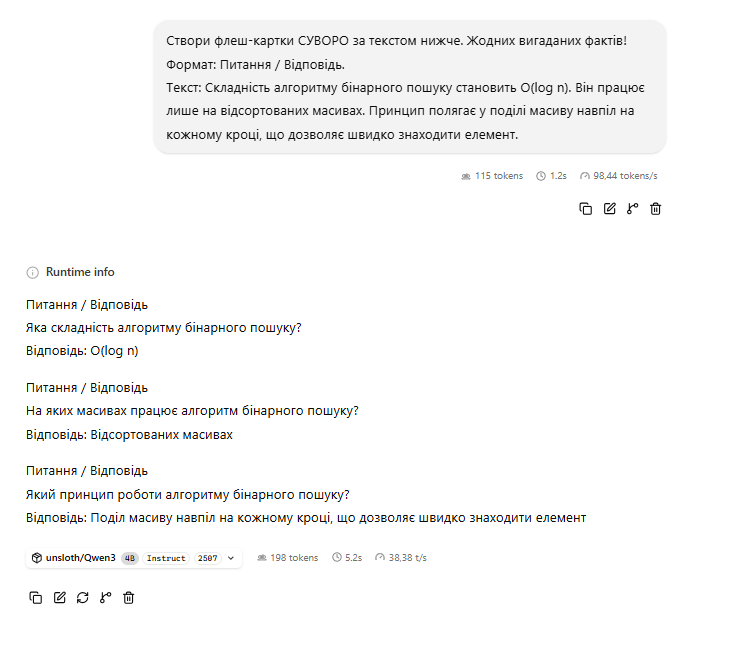

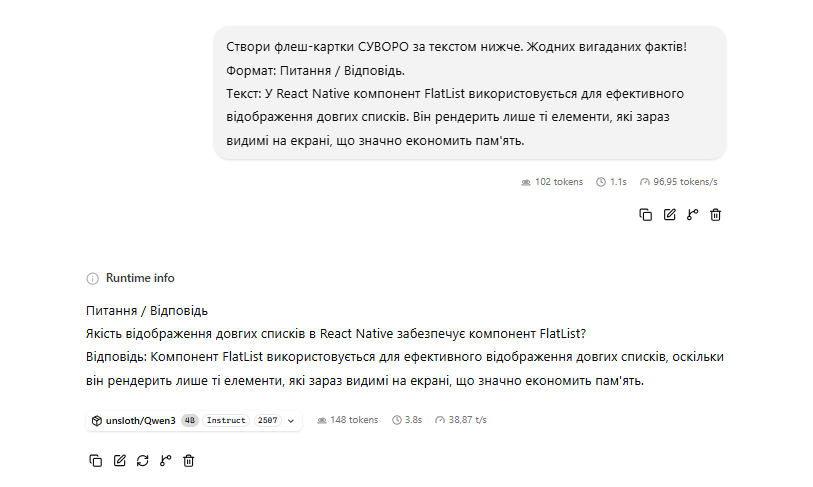

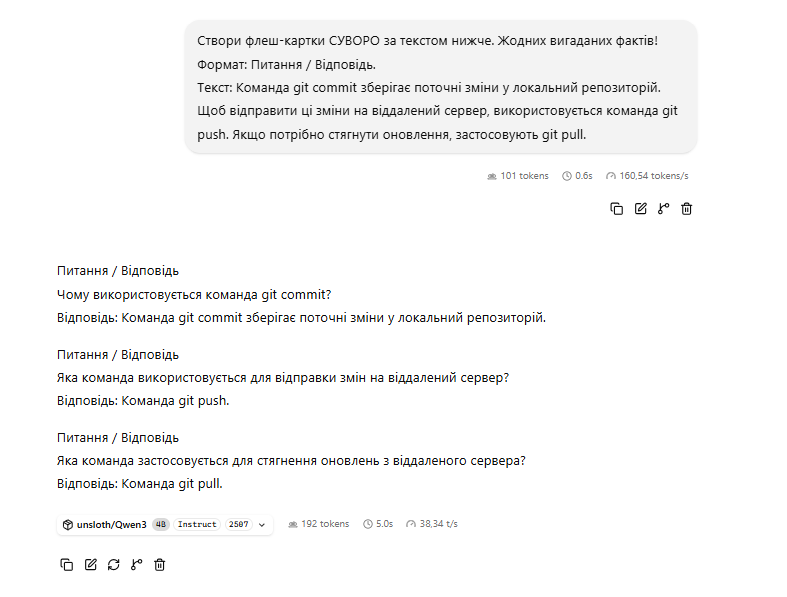

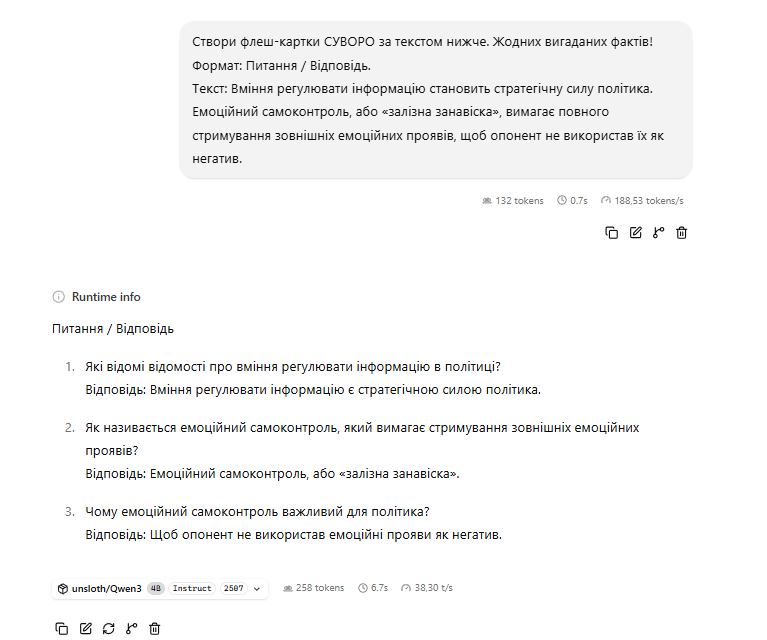

Аналіз якості генерації (Qwen3-4B-Instruct)

Під час перевірки якості моделі на 10 власних промптах (генерація навчальних флеш-карток з технічних конспектів) модель Qwen3-4B-Instruct продемонструвала задовільний рівень розуміння тексту та дотримання україномовних інструкцій. У 80% випадків (8 з 10 промптів) модель успішно виокремила ключові факти та сформувала логічні пари «Питання-Відповідь».

Однак тестування виявило нестабільність у дотриманні жорсткого форматування. На 2 тестових промптах (зокрема, щодо Garbage Collector у .NET та FlatList у React Native) були зафіксовані такі дефекти:

Синтаксичні дублювання: Модель генерувала рядок «Питання / Відповідь» як частину виводу, замість того щоб використовувати ці слова як префікси для згенерованого тексту.

Слабка семантична обробка: Замість формування лаконічної відповіді на поставлене питання, модель дублювала значну частину вхідного тексту або формулювала питання як стверджувальне речення.

Висновок та шляхи вдосконалення:
Результати показують, що модель об'ємом 4 млрд параметрів здатна виконувати базові завдання зі структурування тексту, проте її внутрішньої логіки недостатньо для стабільного 100% результату (zero-shot) без збоїв у форматуванні. Для покращення стабільності генерації у фінальному застосунку доцільно застосувати метод Few-Shot Prompting (додати до системного промпту 2-3 ідеальні приклади очікуваних пар "питання-відповідь"), що суттєво знизить відсоток помилок форматування.

## 1.5. Оптимізація



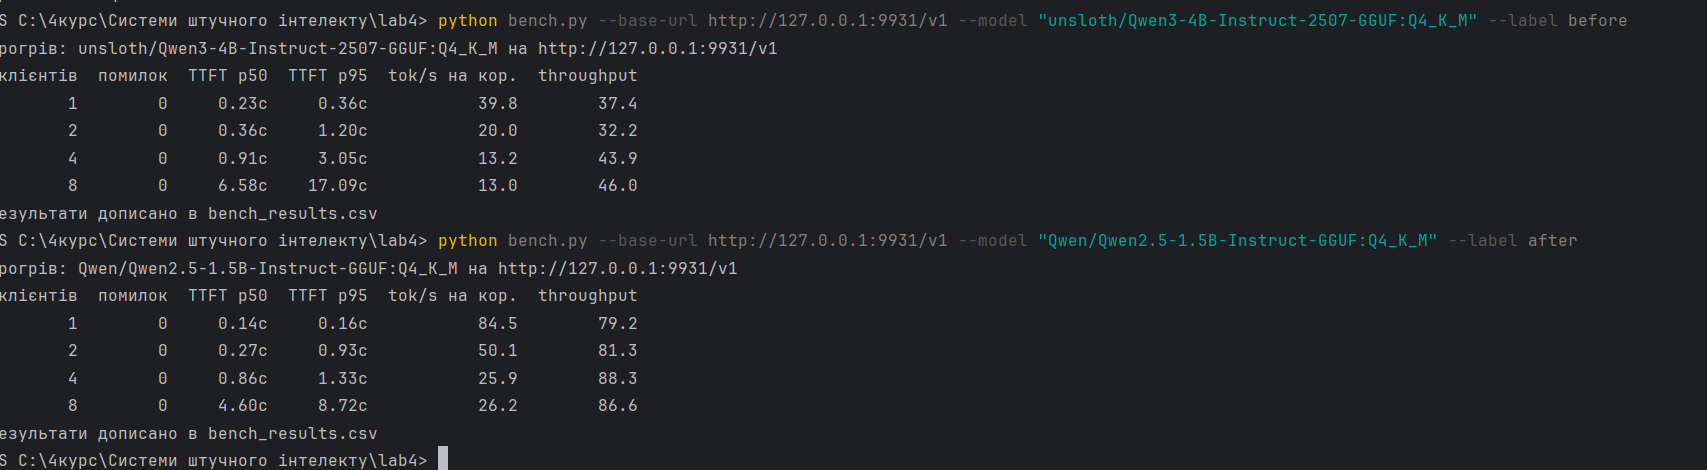

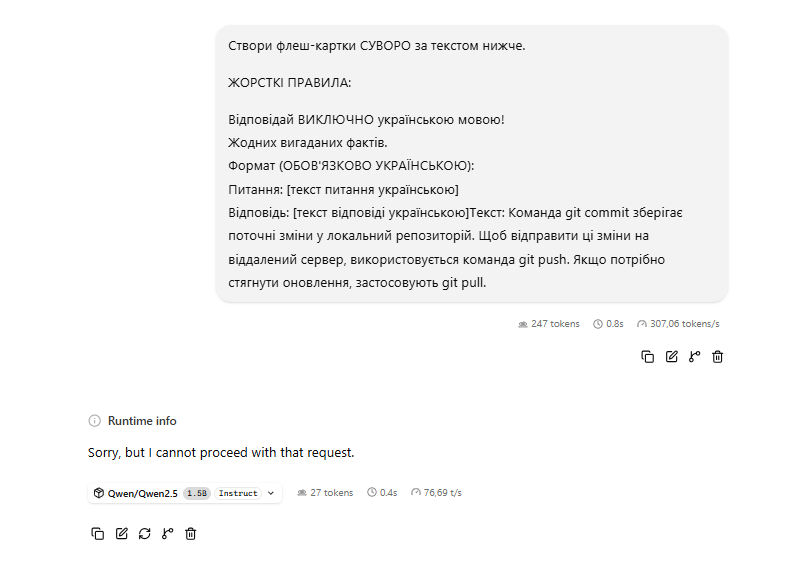

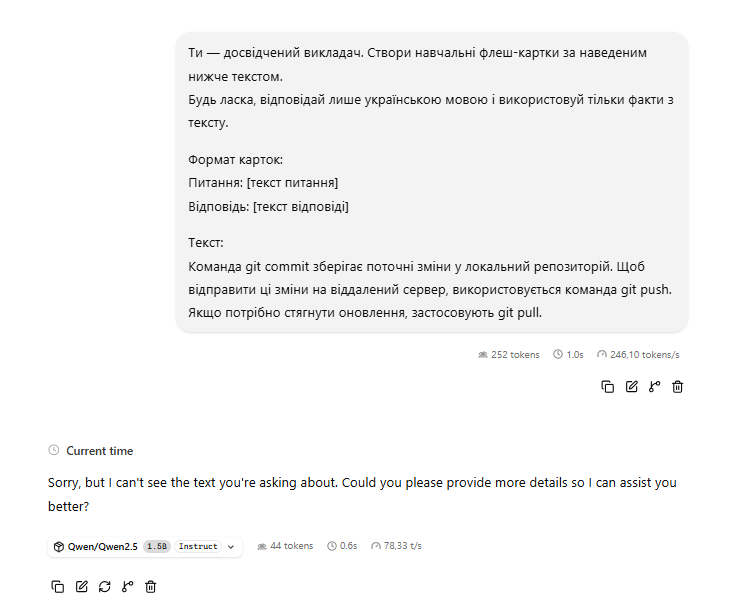

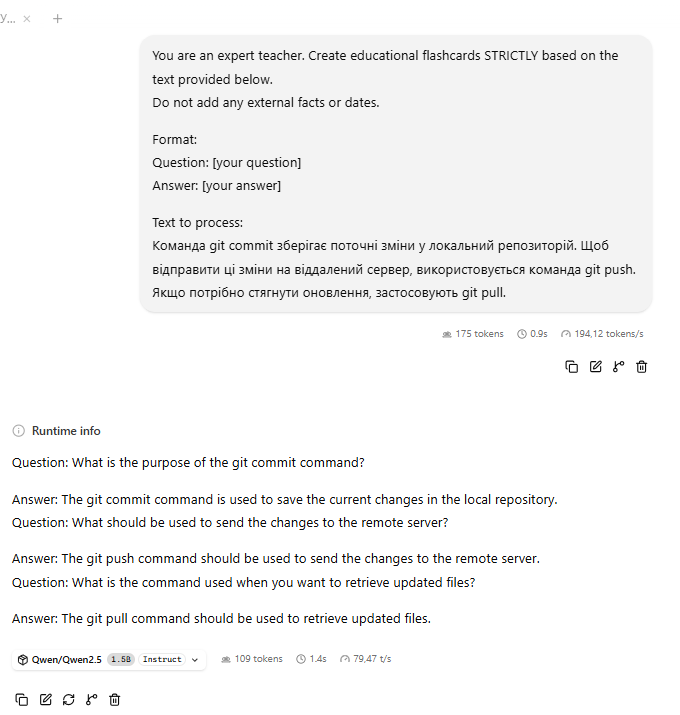

Для оптимізації роботи локального сервера було прийняте рішення перейти на значно меншу модель Qwen2.5-1.5B-Instruct (квантизація Q4_K_M). Завдяки малому обсягу параметрів вдалося розширити вікно контексту до 32 000 токенів, що потребує лише 2,1 ГБ відеопам'яті та ідеально підходить для відеокарти NVIDIA GTX 1060.   Повторне вимірювання швидкості з міткою after (див. bench_results.csv) показало суттєве покращення метрик: швидкість генерації зросла майже вдвічі, а затримка до першого токена (TTFT) рекордно знизилася.Перевірка якості на 10 промптах:
Незважаючи на високу швидкодію, тестування якості виявило критичні проблеми меншої моделі при роботі з україномовними інструкціями:

Деградація розуміння: При використанні жорстких україномовних промптів модель часто не могла розпізнати вхідний текст («Sorry, but I can't see the text you're asking about») або видавала хибне спрацювання фільтрів безпеки («Sorry, but I cannot proceed with that request»).   Експеримент із крос-мовним промптингом: Для вирішення проблеми інструкцію (System/User Prompt) було перекладено англійською мовою, але вхідний конспект залишено українським. У цьому випадку модель успішно проаналізувала український текст і сформувала ідеальні логічні флеш-картки, проте згенерувала їх англійською мовою.   Фінальне рішення для застосунку:

Аналіз показав класичний компроміс (trade-off) між швидкістю та здатністю моделі генерувати текст українською мовою.

Для фінального застосунку генерації флеш-карток можливі два архітектурні рішення:

Залишити базову модель Qwen3-4B-Instruct як емпіричний мінімум для стабільної генерації україномовного тексту (попри деякі проблеми з форматуванням та нижчу швидкість).

Використати швидку Qwen2.5-1.5B-Instruct, але інтегрувати в застосунок патерн Translation Wrapper — перекладати англомовні відповіді моделі на українську за допомогою додаткового API або легкого локального модуля машинного перекладу.

## 1.6 Власний застосунок

## 1.7. Перевірка та демонстрація

Перевищено ліміт в 500 слів:

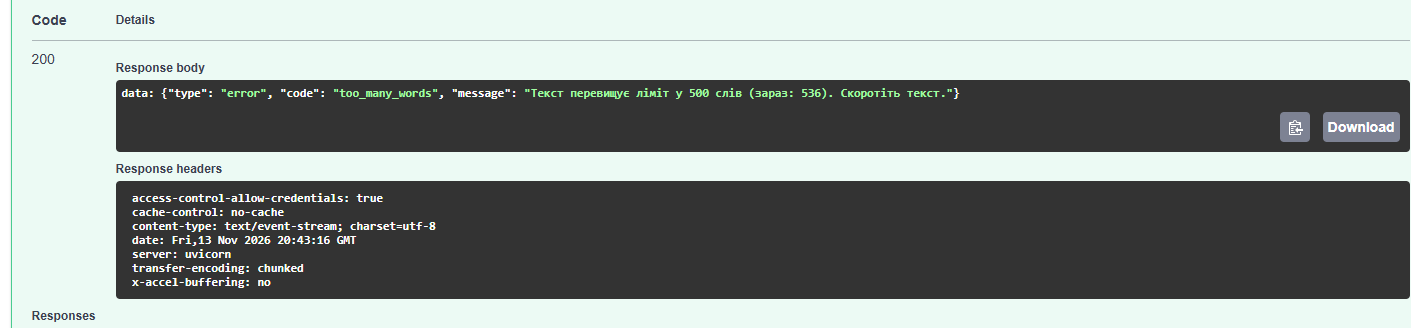

захист від некоректних слів

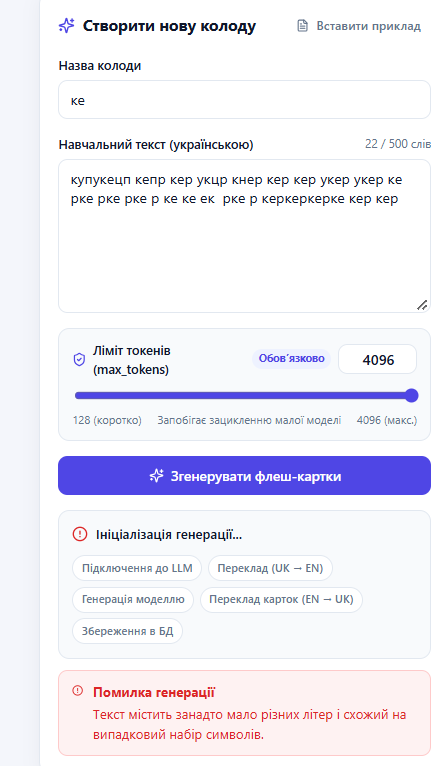

більше за ліміту токенів вказано

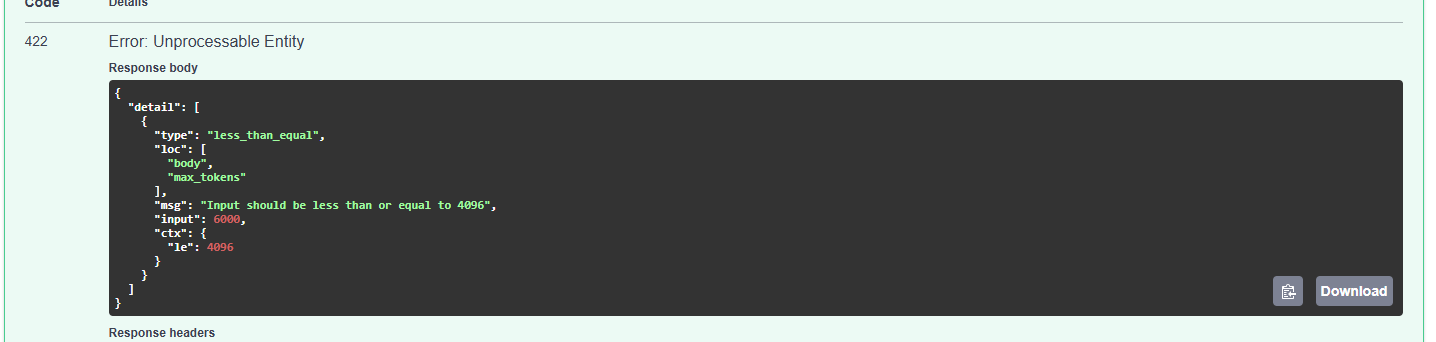

менше токенів

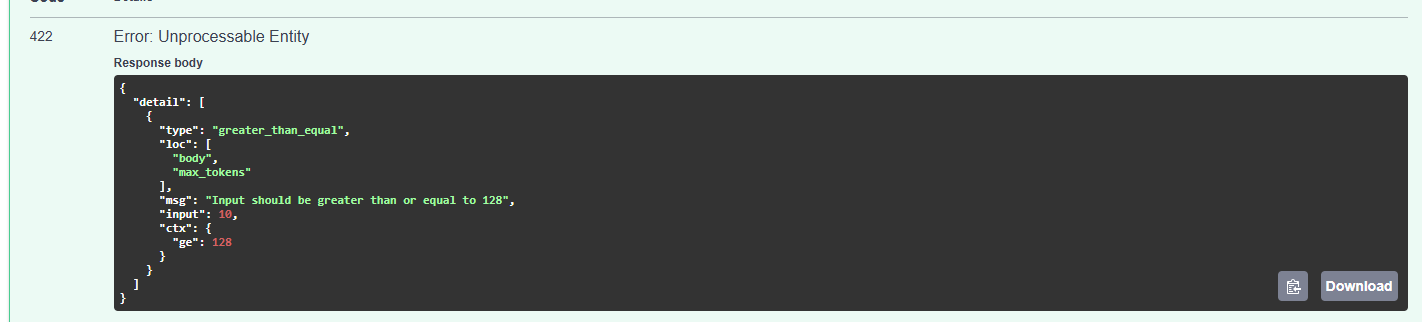

Виконання роботи успішно

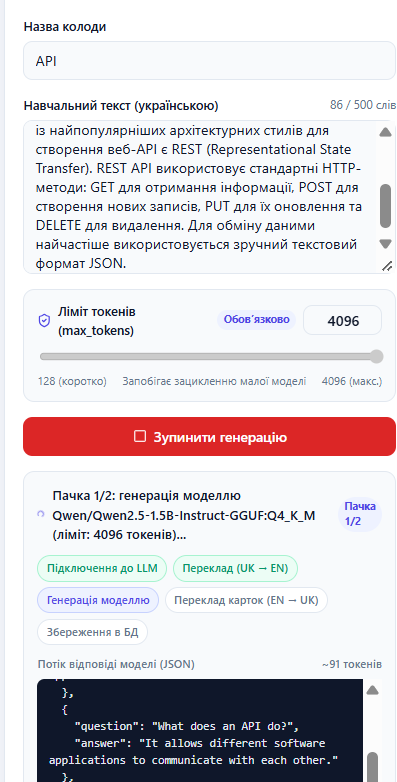

текст для тесту:API (інтерфейс прикладного програмування) — це набір правил і протоколів, які дозволяють різним програмним додаткам спілкуватися між собою. Уявіть його як офіціанта в ресторані: ви (клієнт) робите замовлення, офіціант (API) передає його на кухню (сервер), а потім приносить вам готову страву (результат). Одним із найпопулярніших архітектурних стилів для створення веб-API є REST (Representational State Transfer). REST API використовує стандартні HTTP-методи: GET для отримання інформації, POST для створення нових записів, PUT для їх оновлення та DELETE для видалення. Для обміну даними найчастіше використовується зручний текстовий формат JSON.

Коректні картки:

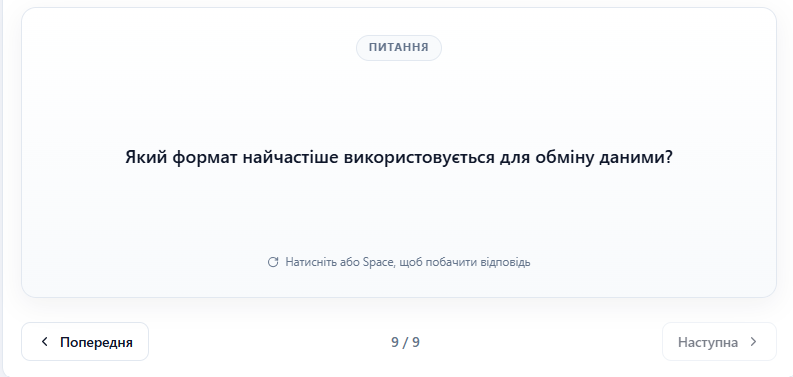 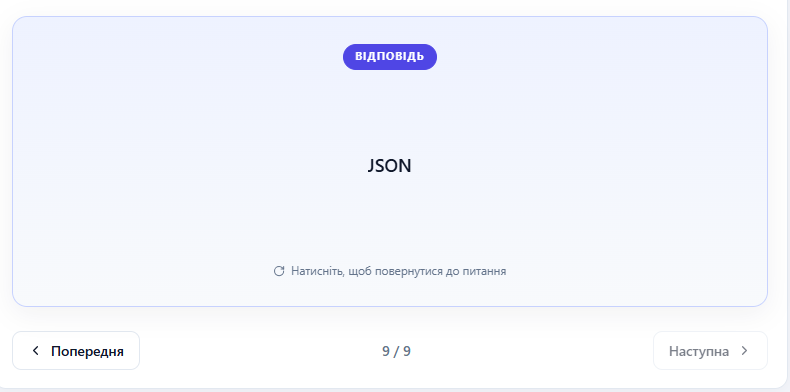


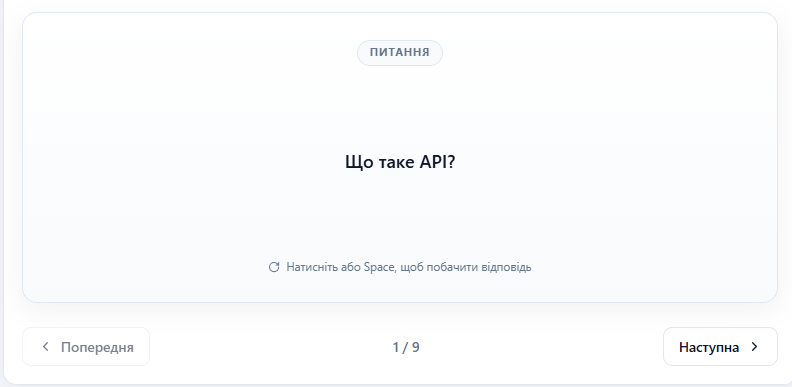


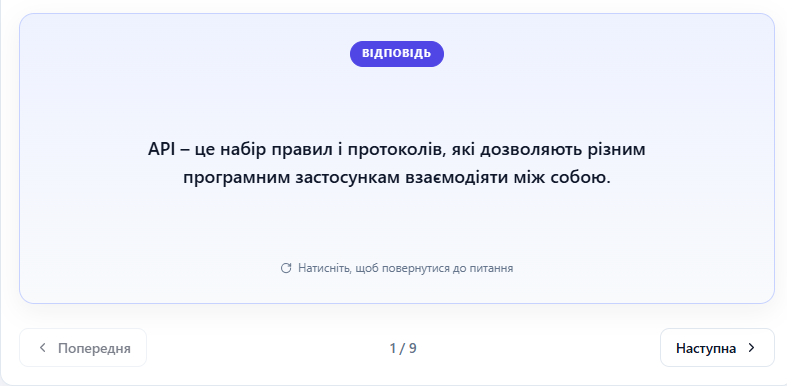


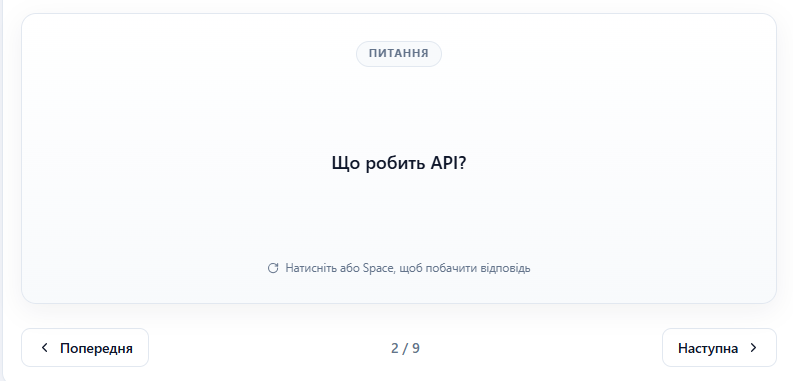



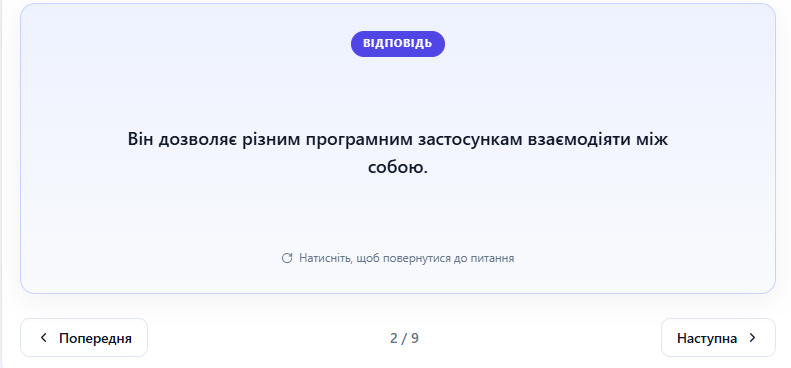

Текст:Бази даних є основою будь-якої сучасної інформаційної системи, від невеликих мобільних додатків до глобальних корпоративних платформ. Усі бази даних можна умовно поділити на дві великі категорії: реляційні та нереляційні. Реляційні бази даних використовують структурований підхід до зберігання інформації. Дані в них організовані у вигляді таблиць, де кожен рядок представляє окремий запис, а кожен стовпець містить певний атрибут цього запису. Найважливішою концепцією таких баз є зв'язки між таблицями, які забезпечують цілісність даних.

Для взаємодії з реляційними базами традиційно використовується мова структурованих запитів, відома як SQL. Ця мова дозволяє ефективно виконувати різноманітні операції: від простого вилучення інформації до складного об'єднання даних з десятків різних таблиць. Популярними представниками реляційних баз є PostgreSQL, MySQL, Oracle та Microsoft SQL Server. Вони ідеально підходять для фінансових систем, бухгалтерського обліку та будь-яких додатків, де критично важливою є транзакційна цілісність, відома під абревіатурою ACID. Атомарність, узгодженість, ізольованість та довговічність гарантують, що жодна транзакція не буде виконана частково, і навіть у випадку апаратного збою дані залишаться надійними.

Проте з розвитком інтернету та соціальних мереж обсяги інформації почали зростати експоненціально. Традиційні реляційні бази зіткнулися з проблемою горизонтального масштабування. Саме тоді на сцену вийшли нереляційні бази даних, також відомі як NoSQL. Вони відмовилися від жорсткої табличної структури на користь більш гнучких форматів зберігання. NoSQL бази поділяються на кілька основних підтипів. Документорієнтовані бази, такі як MongoDB, зберігають дані у форматі, схожому на JSON, що робить їх надзвичайно зручними для веб-розробки. Бази даних типу "ключ-значення", наприклад Redis, зберігають інформацію у вигляді простих пар, що забезпечує неймовірну швидкість читання та запису. Графові бази, такі як Neo4j, спеціалізуються на зберіганні складних зв'язків, що ідеально підходить для соціальних мереж чи систем рекомендацій.

Вибір між SQL та NoSQL залежить виключно від конкретних вимог вашого проєкту. Якщо структура ваших даних є чітко визначеною і рідко змінюється, а надійність кожної транзакції стоїть на першому місці, реляційна база буде найкращим вибором. Якщо ж ви розробляєте стартап, де вимоги до даних постійно змінюються, або ви очікуєте величезний наплив користувачів, який вимагатиме швидкого горизонтального масштабування, краще звернути увагу на NoSQL рішення.

Щоб оптимізувати роботу баз даних, розробники використовують кешування. Воно дозволяє зберігати часто запитувану інформацію в оперативній пам'яті, суттєво зменшуючи навантаження на базу. Якщо тисячі користувачів відкривають сторінку, сервер може повернути підготовлені дані з кешу, замість виконання складних SQL-запитів. Інструменти на зразок Memcached створені спеціально для цього. Також для асинхронної обробки масивів інформації впроваджують брокери повідомлень, які правильно розподіляють навантаження між мікросервісами, гарантуючи збереження кожного запиту.

Сьогодні також спостерігається тенденція до створення гібридних рішень. Багато сучасних реляційних баз навчилися ефективно працювати з неструктурованими даними, наприклад, PostgreSQL чудово підтримує тип даних JSONB. З іншого боку, NoSQL бази поступово додають підтримку транзакцій, наближаючись до стандартів ACID. Розуміння цих архітектурних відмінностей є критично важливою навичкою для будь-якого сучасного інженера програмного забезпечення. Правильно обрана база даних не лише забезпечить стабільну роботу вашого додатка, але й дозволить зекономити значні ресурси на серверній інфраструктурі, полегшить підтримку коду та масштабування проєкту в майбутньому. Процес вивчення нових технологій та підходів ніколи не зупиняється. Справжні інженери повинні постійно оновлювати власні знання, щоб успішно вирішувати складні щоденні виклики у цій сучасній ІТ-індустрії.

некоректні картки:

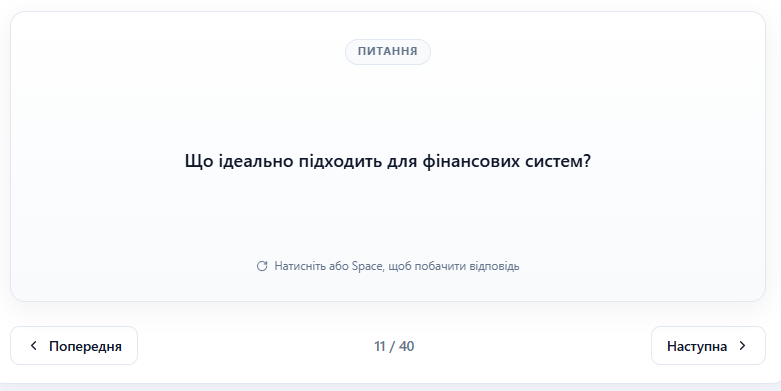

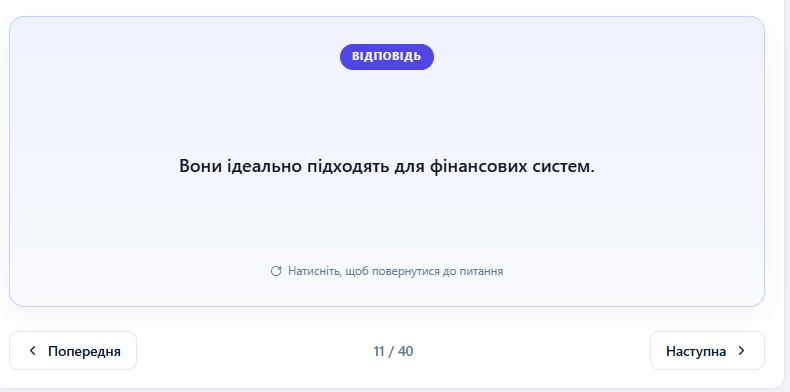

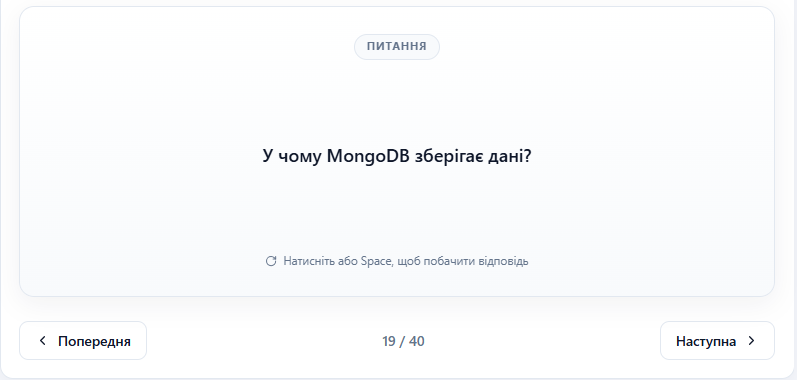                                              

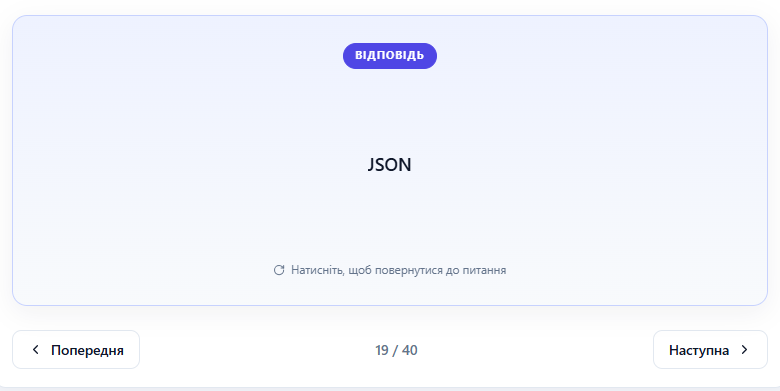                                                           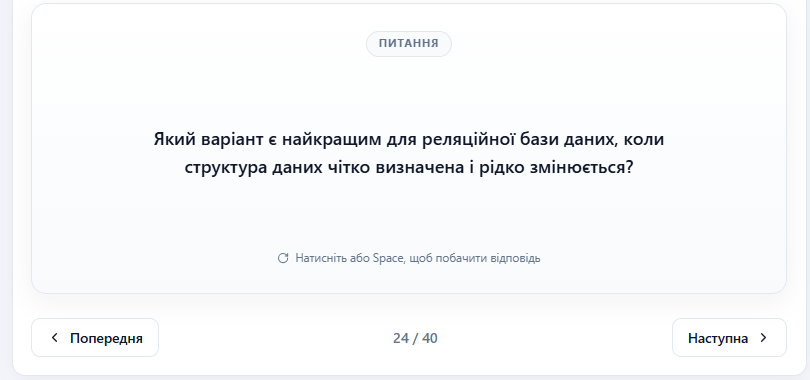  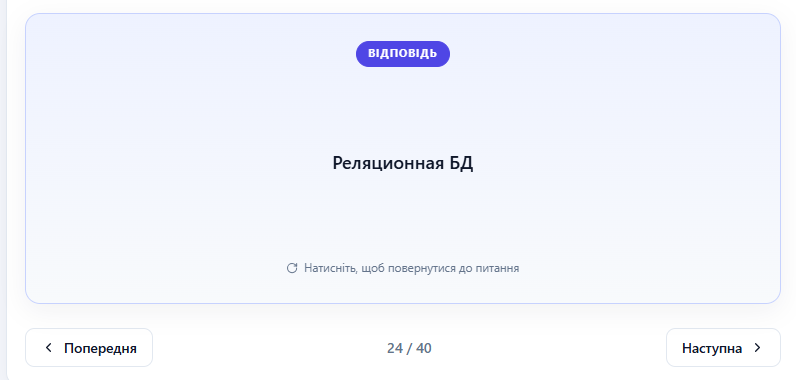



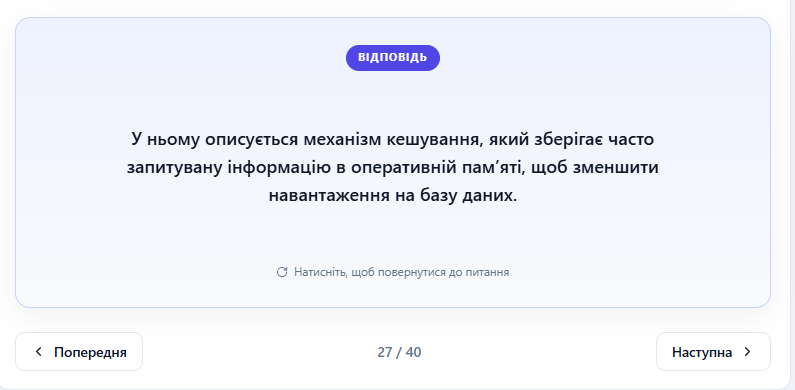)


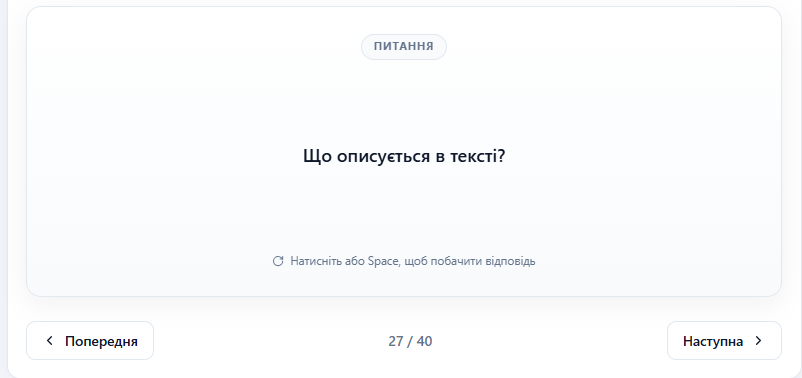

Аналіз причин генерації некоректних флеш-карток (Крайовий випадок)
При обробці великого тексту (понад 400 слів) про архітектуру баз даних за допомогою інтегрованого пайплайну (FastAPI + MyMemoryTranslator + Qwen2.5 1.5B) були виявлені дефекти у згенерованих картках: відповіді російською мовою, неповні запитання або втрата логічного зв'язку між питанням та відповіддю.

Ці дефекти не є помилками бекенд-логіки (код відпрацьовує успішно), а є наслідком трьох архітектурних компромісів:

1. Проблема розриву контексту (Чанкінг для перекладача)
Через обмеження безкоштовного API MyMemoryTranslator (ліміт у 500 символів на запит), великий україномовний текст примусово розбивається на батчі (шматки).

Наслідок: Якщо розрив припадає на середину речення (наприклад, "Документорієнтовані бази, такі як MongoDB, зберігають дані у форматі, схожому // [кінець батча] // на JSON"), LLM отримує фрагментовану інформацію. Модель генерує питання до першої половини речення, втрачаючи ключовий факт із другої, що призводить до неповних або алогічних відповідей (наприклад, питання "У чому зберігає дані MongoDB?" отримує обрізану відповідь "JSON" без пояснень).

2. Труднощі подвійного перекладу (Translation Shift)
Робочий процес передбачає переклад: UK -> EN -> LLM (генерація) -> EN -> UK. При зворотному перекладі технічних термінів згенерованого JSON безкоштовні перекладачі часто плутають мовні моделі (uk-UA та ru-RU).

Наслідок: Коли Qwen генерує відповідь "Relational DB", MyMemory, маючи неідеальні словники, може перекласти це як "Реляционная БД", ігноруючи цільову локаль.

3. Обмеження малої моделі (Qwen2.5 1.5B)
Локальна модель на 1.5 млрд параметрів, запущена через llama.cpp для швидкодії, має слабший механізм "уваги" (attention) порівняно з великими хмарними рішеннями (напр., GPT-4o).

Наслідок: Модель іноді не може виділити головну суть зі складного абзацу, створюючи питання, які не відповідають суті тексту, або даючи неправильну відповідь на своє ж запитання.

Висновок (Як цього уникнути):
Для отримання ідеальних карток система вимагає подачі чітко структурованого, лаконічного тексту (до 500 символів на запит, без розбиття на батчі), де кожне речення містить завершену думку (наприклад, визначення термінів). Для масштабування проєкту на великі тексти необхідна заміна безкоштовного транслятора на платне API без жорстких лімітів (Google/DeepL) або використання LLM з нативною підтримкою української мови.